In [1]:
import awkward as ak
import numba
import numpy as np
import pandas as pd
import awkward as ak
import vector
import numba
import torch
from torch import nn 
from torch.optim import RAdam
from scipy.special import softmax
import h5py
import yaml
import argparse

import seaborn as sns

from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_curve, auc
import onnxruntime    # to inference ONNX models, we use the ONNX Runtime
vector.register_numba()
vector.register_awkward()
import os
import json
import onnx

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D
import mplhep as hep
hep.style.use(hep.style.ROOT)

from importlib import reload
from sklearn.preprocessing import QuantileTransformer
from copy import deepcopy
import numpy as np
from scipy.stats import norm
from sklearn.base import BaseEstimator, TransformerMixin
from multiprocessing import Pool, cpu_count
from concurrent.futures import ThreadPoolExecutor, as_completed
from sklearn.preprocessing import StandardScaler
from torch.utils.data import TensorDataset, DataLoader

In [6]:
dctr_input = "/eos/cms/store/group/phys_higgs/ttHbb/ntuples/ttHbb_export/training_5wps_multiplewp/no_triggerSF/semilep_channel/dctr_inputs/dctr_datasets/2024/dctr_dataset_5j3b_1L_2024_baseline_test_2852508.parquet"
spanet_model = "/eos/cms/store/group/phys_higgs/ttHbb/ntuples/ttHbb_export/training_5wps_multiplewp/no_triggerSF/semilep_channel/spanet_v0_1Lchannel.onnx"
# output folder of the DCTR training job (SAVE_FOLDER in scripts/submit_dctr_two_classifiers_disco.sh)
model_folder = "/eos/home-g/gbonomel/projects/www/analysis_note/1L_channel/dctr_2024"
# DisCo lambda of the model to use, written as in lambdas_disco of the training config (e.g. 0, 0.01, 0.1, 1)
lambda_dctr = 0.01
save_folder = "/eos/home-g/gbonomel/projects/www/analysis_note/1L_channel/dctr_2024/best_model"

# files written by the training job
quantile_transf = os.path.join(model_folder, "tthbb_vs_bkg_quantile_transformer.npz")
dctr_model = os.path.join(model_folder, f"best_model/dctr_model_lambda{lambda_dctr}_scripted.pt")
dctr_model_info = os.path.join(model_folder, f"best_model/dctr_model_lambda{lambda_dctr}_inputs.json")
# ONNX export of the DCTR model, next to the TorchScript one
onnx_model_path = os.path.join(model_folder, f"dctr_model_lambda{lambda_dctr}_2024.onnx")

# ensure save folder exists
os.makedirs(save_folder, exist_ok=True)

CMAP_10 = [
    "#3f90da",
    "#ffa90e",
    "#bd1f01",
    "#94a4a2",
    "#832db6",
    "#a96b59",
    "#e76300",
    "#b9ac70",
    "#717581",
    "#92dadd",
]

In [7]:
labels = {
    "tthbb": 1,
    "ttbb": 2,
    "ttcc": 3,
    "ttlf": 4,
}

In [8]:
# CR/SR definition and input order used in the DCTR training
with open(dctr_model_info) as f:
    dctr_info = json.load(f)
tthbb_transformed_min = dctr_info["cr_cuts"]["tthbb_transformed_min"]
tthbb_transformed_max = dctr_info["cr_cuts"]["tthbb_transformed_max"]
ttlf_max = dctr_info["cr_cuts"]["ttlf_max"]
dctr_info

{'input_names': ['ht',
  'bjets_ht',
  'lightjets_ht',
  'drbb_min',
  'detabb_min',
  'dphibb_min',
  'drbb_avg',
  'mbb_closest',
  'mbb_min',
  'mbb_max',
  'bjet_pt_3',
  'bjet_eta_3',
  'njet'],
 'rf': 0.7261654916636163,
 'w_norm': 1.0,
 'cr_cuts': {'tthbb_transformed_min': 0.4,
  'tthbb_transformed_max': 0.75,
  'ttlf_max': 0.2},
 'lambda_disco': 0.01}

In [9]:
def get_cr_mask(scores, tthbb_transformed_min, tthbb_transformed_max, ttlf_max):
    mask = (
        (scores["tthbb_vs_bkg"] >= tthbb_transformed_min) &
        (scores["tthbb_vs_bkg"] < tthbb_transformed_max) &
        (scores["ttlf"] < ttlf_max)
    )
    return mask 

def get_sr_mask(scores, tthbb_transformed_min, tthbb_transformed_max, ttlf_max):
    mask = (
        (scores["tthbb_vs_bkg"] >= tthbb_transformed_max) &
        (scores["ttlf"] < ttlf_max)
    )
    return mask

In [10]:
class WeightedQuantileTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, n_quantiles=1000, output_distribution='normal'):
        self.n_quantiles = n_quantiles
        self.output_distribution = output_distribution

    def save(self, filename):
        np.savez(
            filename,
            quantiles=self.quantiles_,
            reference_quantiles=self.reference_quantiles_,
            n_quantiles=self.n_quantiles,
            output_distribution=self.output_distribution,
        )

    def load(self, filename):
        data = np.load(filename)
        self.quantiles_ = data["quantiles"]
        self.reference_quantiles_ = data["reference_quantiles"]
        self.n_quantiles = int(data["n_quantiles"])
        self.output_distribution = str(data["output_distribution"])
    
    def _weighted_quantiles(self, X, weights):
        # Calculate weighted quantiles
        sorted_indices = np.argsort(X)
        X_sorted = X[sorted_indices]
        weights_sorted = weights[sorted_indices]
        cum_weights = np.cumsum(weights_sorted) / np.sum(weights_sorted)
        
        # Interpolate to get quantiles
        quantiles = np.interp(np.linspace(0, 1, self.n_quantiles), cum_weights, X_sorted)
        return quantiles
    
    def fit(self, X, y=None, sample_weight=None):
        if sample_weight is None:
            raise ValueError("Sample weights must be provided.")
        
        self.quantiles_ = self._weighted_quantiles(X, sample_weight)
        
        if self.output_distribution == 'normal':
            self.reference_quantiles_ = norm.ppf(np.linspace(0, 1, self.n_quantiles))
        elif self.output_distribution == 'uniform':
            self.reference_quantiles_ = np.linspace(0, 1, self.n_quantiles)
        else:
            raise ValueError(f"Unknown output distribution '{self.output_distribution}'.")
        
        return self
    
    def transform(self, X):
        # Interpolate based on weighted quantiles
        transformed_X = np.interp(X, self.quantiles_, self.reference_quantiles_)
        return transformed_X

DCTR model from `scripts/dctr_two_classifiers_disco.py` (two classifiers + DisCo): the TorchScript export takes the raw inputs and returns the DCTR weight $w = r\,(1 + b) - b$ directly.
The weight is a shape correction on top of the inclusive normalisation `rf` (weighted mean ~1 on ttbb in the CR).

Open the spanet output to get spanet scores and weights. Add the spanet scores as a field to the DCTR parquet data frame

In [11]:
# load the dctr model and dctr inputs
df = ak.from_parquet(dctr_input)

In [12]:
# extract weights by event
weights = ak.to_numpy(df.event.weight)

In [13]:
df.fields

['JetGood',
 'LeptonGood',
 'PuppiMET',
 'events',
 'spanet_output',
 'tthbb',
 'tthnonbb',
 'ttbb',
 'ttcc',
 'ttlf',
 'singletop',
 'ttv',
 'vjets',
 'data',
 'dctr',
 'metadata',
 'BJetGood',
 'event']

In [14]:
njet = ak.num(df.JetGood)

In [15]:
# discriminate between ttcc (1) and ttllf (0)
spanet_output_ttcc_vs_ttlf = df.spanet_output.ttcc / (df.spanet_output.ttlf + df.spanet_output.ttcc)
spanet_output_tthbb_vs_bkg = df.spanet_output.tthbb / (df.spanet_output.tthbb + df.spanet_output.ttbb + df.spanet_output.ttcc + df.spanet_output.ttlf)
# add spanet_output_ttcc_vs_ttlf to df.spanet_output fields
df.spanet_output = ak.with_field(df.spanet_output, spanet_output_ttcc_vs_ttlf, "ttcc_vs_ttlf")
df.spanet_output = ak.with_field(df.spanet_output, spanet_output_tthbb_vs_bkg, "tthbb_vs_bkg")

In [16]:
df.spanet_output.fields

['tthbb',
 'ttbb',
 'ttcc',
 'ttlf',
 'ttv',
 'singletop',
 'tth_nonbb',
 'ttcc_vs_ttlf',
 'tthbb_vs_bkg']

In [17]:
# true labels from dctr input to use as mask by sample
true_labels = {}
for label in labels:
    true_labels[label] = ak.to_numpy(df[f"{label}"]).astype(bool)    
true_labels

{'tthbb': array([ True,  True, False, ...,  True, False,  True]),
 'ttbb': array([False, False,  True, ..., False, False, False]),
 'ttcc': array([False, False, False, ..., False,  True, False]),
 'ttlf': array([False, False, False, ..., False, False, False])}

In [18]:
new_labels = list(labels.keys()) 
neyman_var = ["ttcc_vs_ttlf", "tthbb_vs_bkg"]
new_labels.extend(neyman_var)
new_labels

['tthbb', 'ttbb', 'ttcc', 'ttlf', 'ttcc_vs_ttlf', 'tthbb_vs_bkg']

In [19]:
pred_labels = {}
for label in new_labels:
    pred_labels[label] = ak.to_numpy(df.spanet_output[f"{label}"])
pred_labels

{'tthbb': array([0.42348835, 0.11441693, 0.22521916, ..., 0.0945847 , 0.01970145,
        0.27543667], dtype=float32),
 'ttbb': array([0.18015586, 0.08765995, 0.2631924 , ..., 0.0999014 , 0.23125039,
        0.21580079], dtype=float32),
 'ttcc': array([0.05428002, 0.18147916, 0.09279764, ..., 0.1254693 , 0.21482386,
        0.07051578], dtype=float32),
 'ttlf': array([0.04029994, 0.14403133, 0.09070522, ..., 0.15250163, 0.26261297,
        0.12167054], dtype=float32),
 'ttcc_vs_ttlf': array([0.57390606, 0.55752164, 0.50570136, ..., 0.45137563, 0.44995242,
        0.36691362], dtype=float32),
 'tthbb_vs_bkg': array([0.606522  , 0.21686822, 0.33519027, ..., 0.20019744, 0.02704799,
        0.40302467], dtype=float32)}

In [20]:
# transform the tthbb score with quantile transformation
is_tthbb = true_labels["tthbb"]
score_tthbb = ak.to_numpy(pred_labels["tthbb_vs_bkg"][is_tthbb])
weights_tthbb = weights[is_tthbb]
pred_labels_transformed = deepcopy(pred_labels)
transformer = WeightedQuantileTransformer(n_quantiles=10000, output_distribution='uniform')
transformer.load(quantile_transf)
#transformer.save(os.path.join(save_folder, "tthbb_quantile_transformer.npz"))
pred_labels_transformed["tthbb_vs_bkg"] = transformer.transform(pred_labels["tthbb_vs_bkg"])

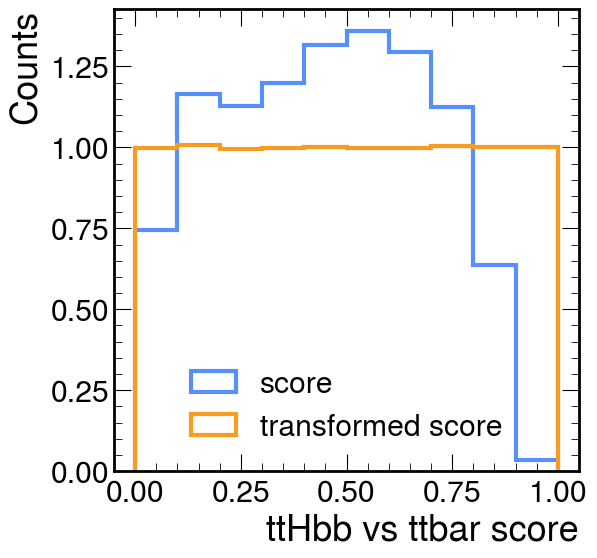

In [21]:
fig, ax = plt.subplots(1,1, figsize=[6,6])
ax.hist(pred_labels["tthbb_vs_bkg"][is_tthbb], weights=weights[is_tthbb], bins=10, range=(0,1), histtype="step", linewidth=3, label="score", density=True)
ax.hist(pred_labels_transformed["tthbb_vs_bkg"][is_tthbb], weights=weights[is_tthbb], bins=10, range=(0,1), histtype="step", linewidth=3, label="transformed score", density=True)
ax.legend(loc='best');
ax.set_xlabel("ttHbb vs ttbar score")
ax.set_ylabel("Counts")
fig.savefig(os.path.join(save_folder, "quantile_transf_2024.png"),dpi=300)

In [22]:
# add the spanet output to the df 
spanet_fields = {key: pred_labels_transformed[key] for key in pred_labels_transformed.keys()}
df = ak.with_field(df, ak.zip(spanet_fields), "spanet_output")
df.fields

['JetGood',
 'LeptonGood',
 'PuppiMET',
 'events',
 'tthbb',
 'tthnonbb',
 'ttbb',
 'ttcc',
 'ttlf',
 'singletop',
 'ttv',
 'vjets',
 'data',
 'dctr',
 'metadata',
 'BJetGood',
 'event',
 'spanet_output']

In [23]:
df.spanet_output.fields

['tthbb', 'ttbb', 'ttcc', 'ttlf', 'ttcc_vs_ttlf', 'tthbb_vs_bkg']

In [24]:
df # contains all regions 

<Array [{JetGood: [, ... ] type='2852508 * {"JetGood": var * {"pt": float64, "et...'>

In [25]:
# dctr input variables, in the order of the training
njets = ak.num(df.JetGood)
data = []
bjet_pt_3 = df.BJetGood.pt[:,2]
bjet_eta_3 = df.BJetGood.eta[:,2]
for f in df.events.fields:
    data.append(ak.to_numpy(df.events[f]))
data.append(ak.to_numpy(bjet_pt_3))
data.append(ak.to_numpy(bjet_eta_3))
data.append(ak.to_numpy(njets))
dctr_inputs = np.stack(data).T.astype(np.float32)
input_names = list(df.events.fields) + ["bjet_pt_3", "bjet_eta_3", "njet"]
assert input_names == dctr_info["input_names"], f"inputs {input_names} differ from the training {dctr_info['input_names']}"

In [26]:
dctr_inputs.shape # contains all regions

(2852508, 13)

In [28]:
# the exported model takes the raw inputs (the standardisation is inside the model) and returns the DCTR weight
# w = r (1 + b) - b, with r = data / (ttbb + other bkg) from clf_data and b = other bkg / ttbb from clf_bkg
model = torch.jit.load(dctr_model, map_location="cpu").eval()
print(f"Loaded model from {dctr_model}")

outputs = [[], [], []]
with torch.no_grad():
    for start in range(0, len(dctr_inputs), 500000):
        for o, v in zip(outputs, model.components(torch.from_numpy(dctr_inputs[start:start + 500000]))):
            o.append(v.numpy())
dctr_r, dctr_b, dctr_w_ttbb = (np.concatenate(o) for o in outputs)

Loaded model from /eos/home-g/gbonomel/projects/www/analysis_note/1L_channel/dctr_2024/best_model/dctr_model_lambda0.01_scripted.pt


In [29]:
# Export the DCTR model to ONNX: raw inputs [batch, n_inputs] (order in dctr_info["input_names"]) -> DCTR weight [batch]
import torch.onnx

torch.onnx.export(
    model,
    torch.from_numpy(dctr_inputs[:1]),
    onnx_model_path,
    input_names=['input'],
    output_names=['output'],
    dynamic_axes={'input': {0: 'batch_size'}, 'output': {0: 'batch_size'}},
    opset_version=11,
    do_constant_folding=True,
    verbose=False
)

print(f"Model exported to ONNX format at {onnx_model_path}")

# Verify the ONNX model, and that ONNX Runtime gives the same DCTR weight as the torch model
onnx_model = onnx.load(onnx_model_path)
onnx.checker.check_model(onnx_model)
sess = onnxruntime.InferenceSession(onnx_model_path, providers=["CPUExecutionProvider"])
onnx_w = sess.run(["output"], {"input": dctr_inputs[:100000]})[0]
np.testing.assert_allclose(onnx_w, dctr_w_ttbb[:100000], rtol=1e-5, atol=1e-5)
print("ONNX model verification passed!")

/afs/cern.ch/work/g/gbonomel/envs/jupy/lib/python3.11/site-packages/torch/onnx/utils.py:782: UserWarning: no signature found for builtin <built-in method __call__ of PyCapsule object at 0x7fbce3ddd530>, skipping _decide_input_format
  warnings.warn(f"{e}, skipping _decide_input_format")


Model exported to ONNX format at /eos/home-g/gbonomel/projects/www/analysis_note/1L_channel/dctr_2024/dctr_model_lambda0.01_2024.onnx
ONNX model verification passed!


In [30]:
# add dctr weight and its two components to the df
df = ak.with_field(df, dctr_w_ttbb, "dctr_weight")
df = ak.with_field(df, dctr_r, "dctr_r")
df = ak.with_field(df, dctr_b, "dctr_b")
df.fields

['JetGood',
 'LeptonGood',
 'PuppiMET',
 'events',
 'tthbb',
 'tthnonbb',
 'ttbb',
 'ttcc',
 'ttlf',
 'singletop',
 'ttv',
 'vjets',
 'data',
 'dctr',
 'metadata',
 'BJetGood',
 'event',
 'spanet_output',
 'dctr_weight',
 'dctr_r',
 'dctr_b']

In [31]:
df.events.fields

['ht',
 'bjets_ht',
 'lightjets_ht',
 'drbb_min',
 'detabb_min',
 'dphibb_min',
 'drbb_avg',
 'mbb_closest',
 'mbb_min',
 'mbb_max']

DCTR weight range for the plots: (0.573038125038147, 1.4279761075973512)


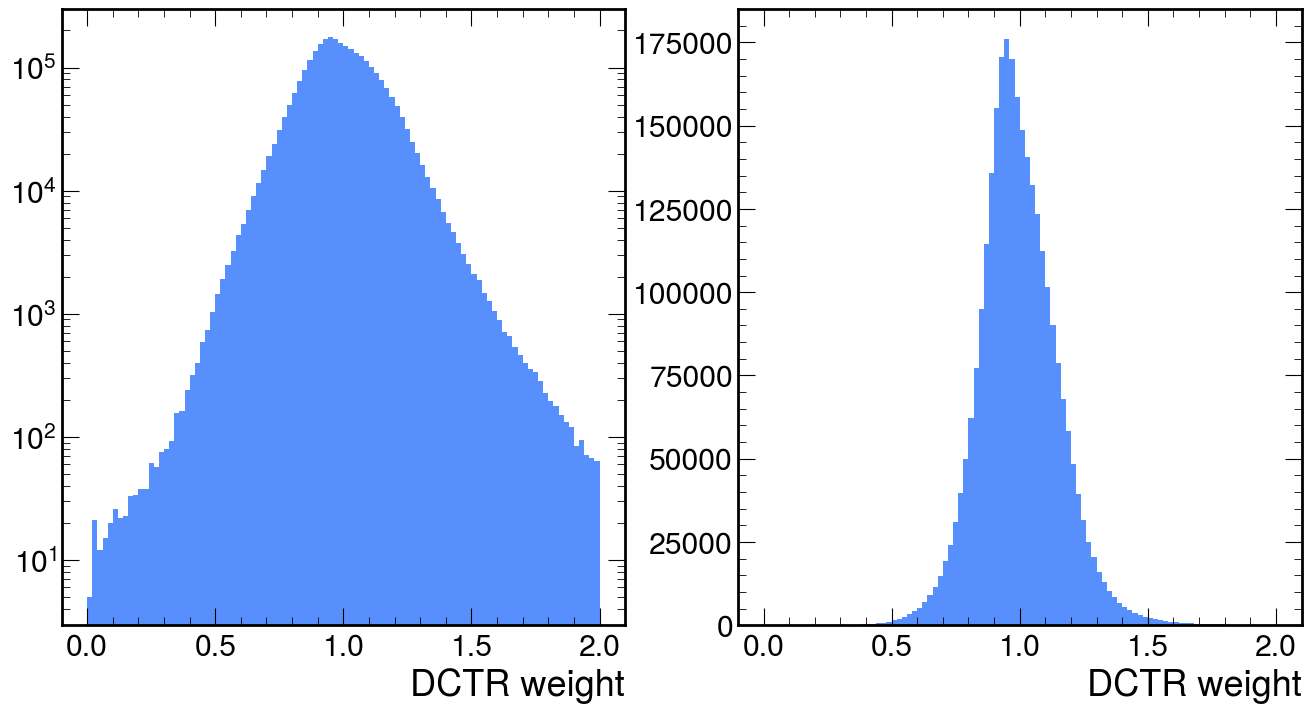

In [32]:
# plotting range of the DCTR weight from the ttbb events (the weight w = r (1 + b) - b can be < 0)
is_ttbb_mc = ak.to_numpy((df.data == 0) & (df.ttbb == 1))
w_range = tuple(np.percentile(dctr_w_ttbb[is_ttbb_mc], [0.5, 99.5]))
print(f"DCTR weight range for the plots: {w_range}")

f, (ax, bx) = plt.subplots(1, 2, figsize=(16,8))
ax.hist(df.dctr_weight, bins=100, range=(0,2))
bx.hist(df.dctr_weight, bins=100, range=(0,2))
ax.set_yscale("log")
ax.set_xlabel("DCTR weight")
bx.set_xlabel("DCTR weight")
f.savefig(os.path.join(save_folder, "dctr_weight_2024.png"),dpi=300)


In [33]:
# print mean and std of dctr weight
print("Mean of DCTR weight:", np.mean(df.dctr_weight))
print("Std of DCTR weight:", np.std(df.dctr_weight))

Mean of DCTR weight: 0.9962763469900873
Std of DCTR weight: 0.25751793252985095


In [34]:
# define all the masks
mask_mc = (df.data == 0)
is_data = (df.data == 1)

mask_signal = mask_mc & (df.tthbb == 1)
mask_ttbb = mask_mc & (df.ttbb == 1)
mask_ttcc = mask_mc & (df.ttcc == 1)
mask_ttlf = mask_mc & (df.ttlf == 1)
mask_singletop = mask_mc & (df.singletop == 1)
#mask_otherbkg = mask_mc & ((df.vjets==1)|(df.ttv==1)|(df.vv==1))
mask_data_minus_minor_bkg = (df.dctr == 1)
masks_njet = {
    "4j": ak.num(df.JetGood) == 4,
    "5j": ak.num(df.JetGood) == 5,
    ">=6j": ak.num(df.JetGood) >= 6,
    #">=7j": ak.num(df.JetGood) >= 7,
}

df.events = ak.with_field(df.events, df.BJetGood[:, 2].pt, "bjet_pt_3")
df.events = ak.with_field(df.events, ak.num(df.BJetGood), "nbjets")
df.events = ak.with_field(df.events, ak.num(df.JetGood), "njets")

In [35]:
# define signal and control region masks
isCR = get_cr_mask(df.spanet_output, tthbb_transformed_min, tthbb_transformed_max, ttlf_max)
isSR = get_sr_mask(df.spanet_output, tthbb_transformed_min, tthbb_transformed_max, ttlf_max)

In [36]:
# count the number of ttbb events in the control region and in the signal region
n_ttbb_CR = ak.sum(mask_ttbb & isCR)
n_ttbb_SR = ak.sum(mask_ttbb & isSR)
n_data_CR = ak.sum(is_data & isCR)
n_data_SR = ak.sum(is_data & isSR)
print(f"Number of ttbb events in Control Region: {n_ttbb_CR}")
print(f"Number of ttbb events in Signal Region: {n_ttbb_SR}")
print(f"Number of data events in Control Region: {n_data_CR}")
print(f"Number of data events in Signal Region: {n_data_SR}")

Number of ttbb events in Control Region: 175095
Number of ttbb events in Signal Region: 49238
Number of data events in Control Region: 6982
Number of data events in Signal Region: 1592


In [37]:
hist_settings = {
    "ht" : (80, 0, 1200),
    "bjets_ht" : (80,0,1200),
    "lightjets_ht": (80, 0, 600),
    "drbb_min": (80, 0, 3),
    "mbb_closest": (80,50, 400),
    "bjet_pt_3": (80, 30, 200),
    "nbjets" : (4, 3,7),
    "njets": (6, 5, 10)
}

cols = [ "ht" , "lightjets_ht", "bjets_ht", "bjet_pt_3", "mbb_closest", "drbb_min"]#, "nbjets"]

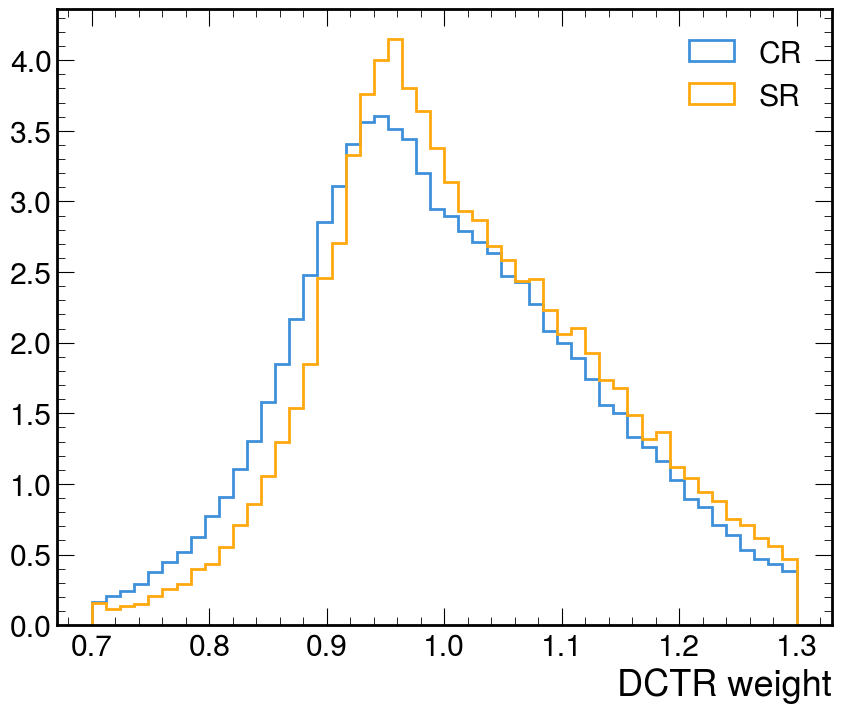

In [38]:
f, axs = plt.subplots(figsize=(10,8))
axs.hist(df[mask_ttbb & isCR].dctr_weight, range=(0.7,1.3), bins=50, histtype="step", linewidth=2, color=CMAP_10[0], label="CR", density=True)
axs.hist(df[mask_ttbb & isSR].dctr_weight, range=(0.7,1.3), bins=50, histtype="step", linewidth=2, color=CMAP_10[1], label="SR", density=True)
axs.set_xlabel("DCTR weight")
axs.legend()

f.savefig(os.path.join(save_folder, "dctr_weight_CR_SR_2024.png"),dpi=300)

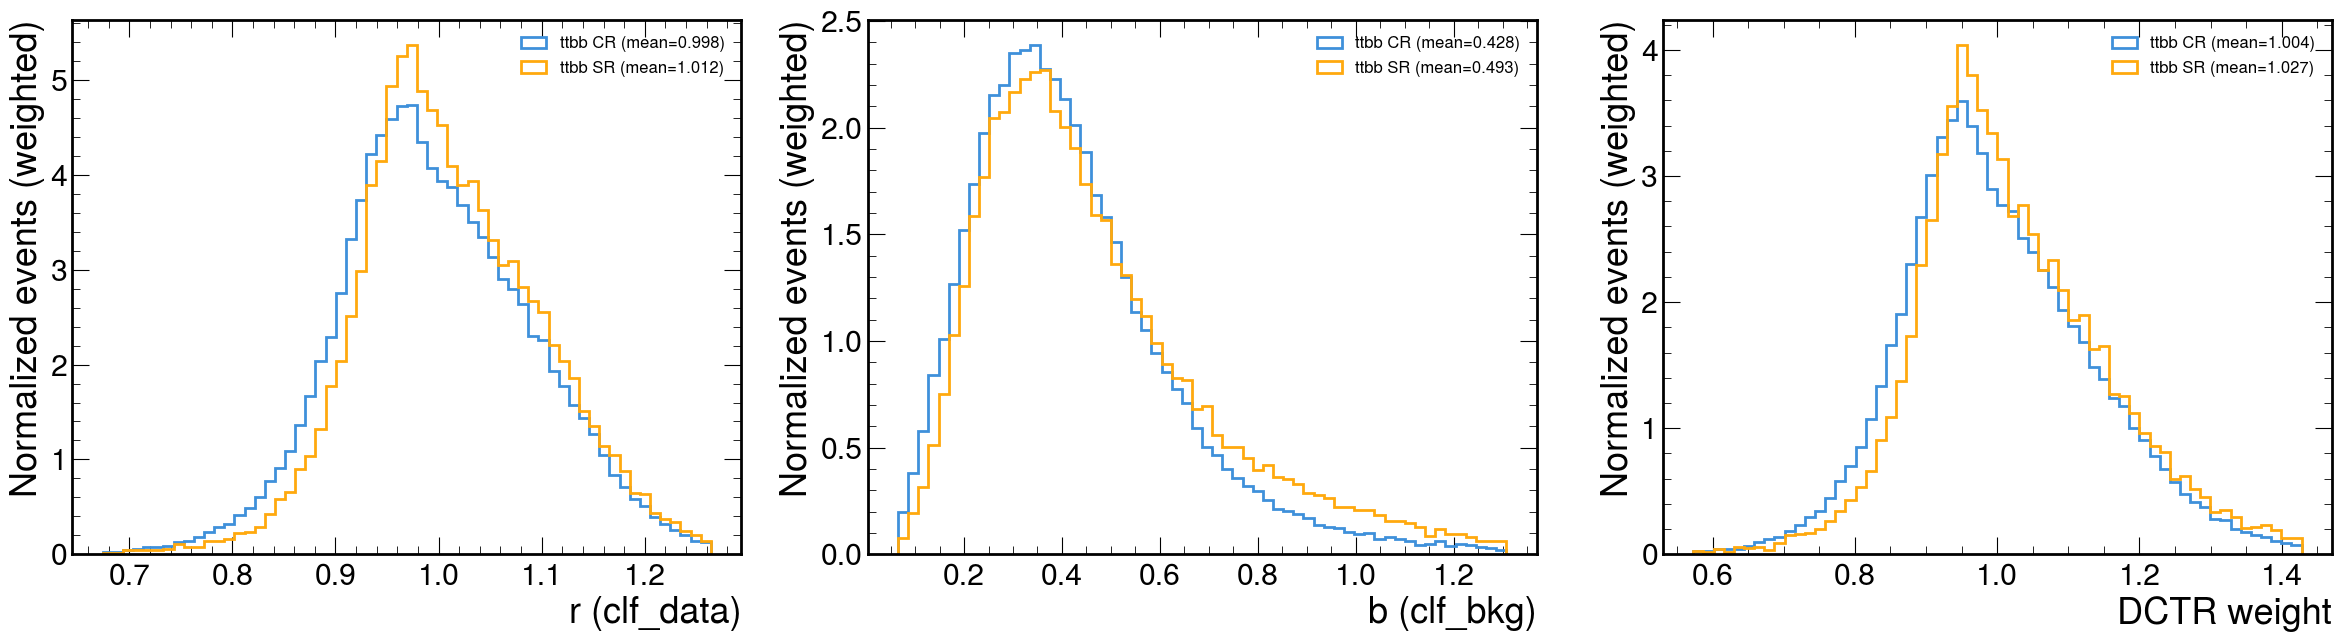

In [39]:
# distributions of r (clf_data), b (clf_bkg) and of the DCTR weight for ttbb events in the CR and SR
is_ttbb_np = ak.to_numpy(mask_ttbb)
f, axs = plt.subplots(1, 3, figsize=(24, 7))
for ax, values, name in zip(axs, [dctr_r, dctr_b, dctr_w_ttbb], ["r (clf_data)", "b (clf_bkg)", "DCTR weight"]):
    rng = tuple(np.percentile(values[is_ttbb_np], [0.5, 99.5]))
    for (region, reg_mask), color in zip([("CR", isCR), ("SR", isSR)], [CMAP_10[0], CMAP_10[1]]):
        t = is_ttbb_np & ak.to_numpy(reg_mask)
        ax.hist(values[t], weights=weights[t], bins=60, range=rng, histtype="step", linewidth=2, color=color, density=True,
                label=f"ttbb {region} (mean={np.average(values[t], weights=weights[t]):.3f})")
    ax.set_xlabel(name)
    ax.set_ylabel("Normalized events (weighted)")
    ax.legend(fontsize=12)
plt.tight_layout()
f.savefig(os.path.join(save_folder, "dctr_components_CR_SR_2024.png"), dpi=300)

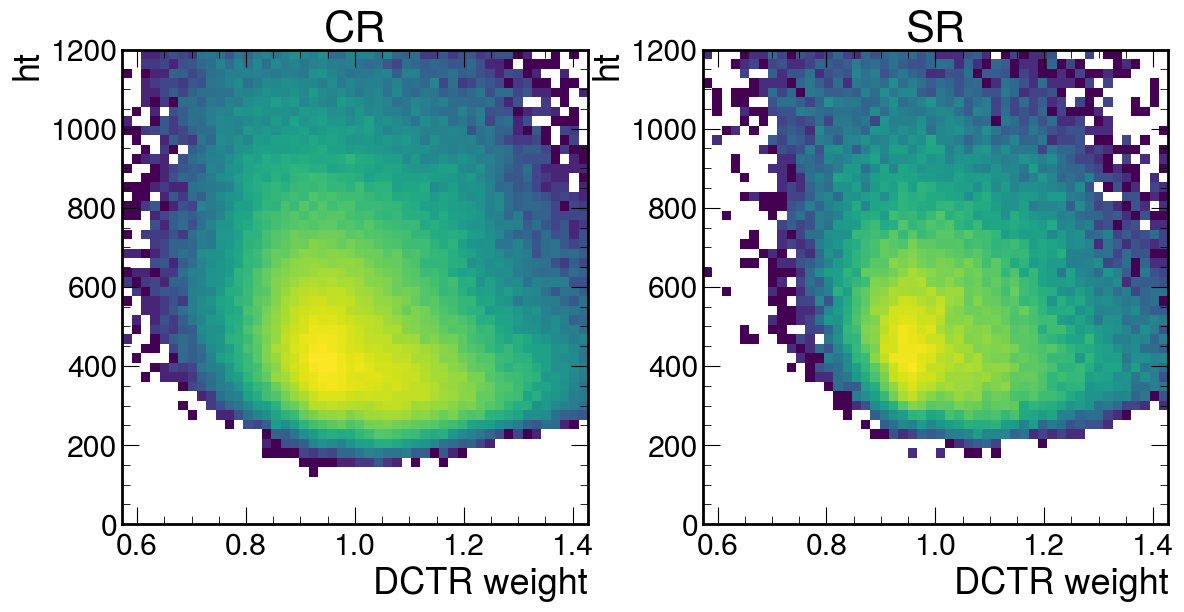

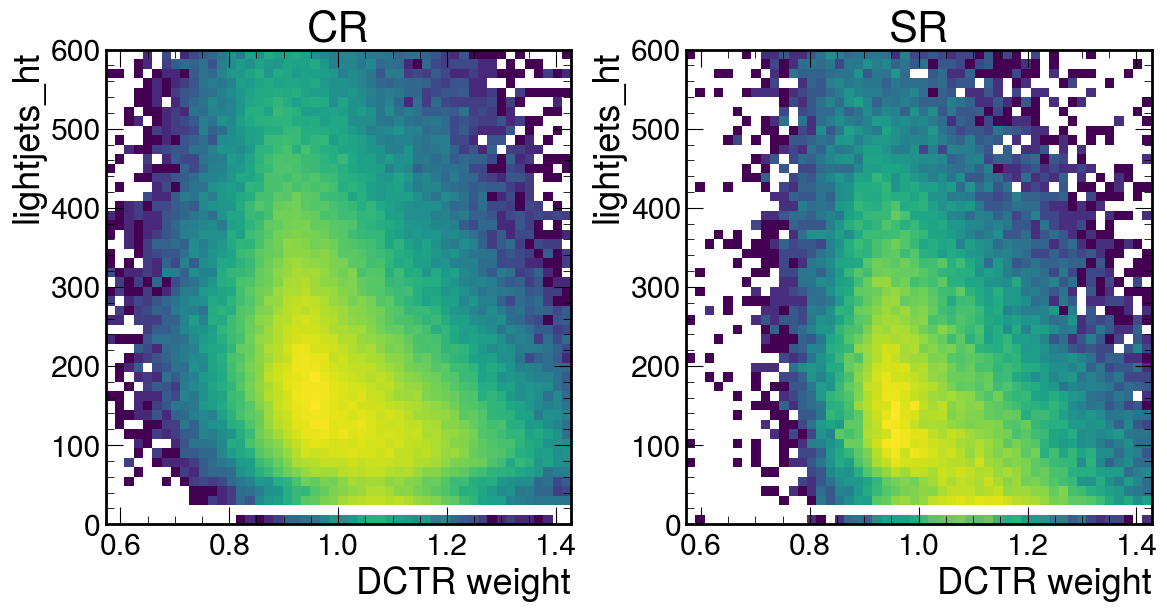

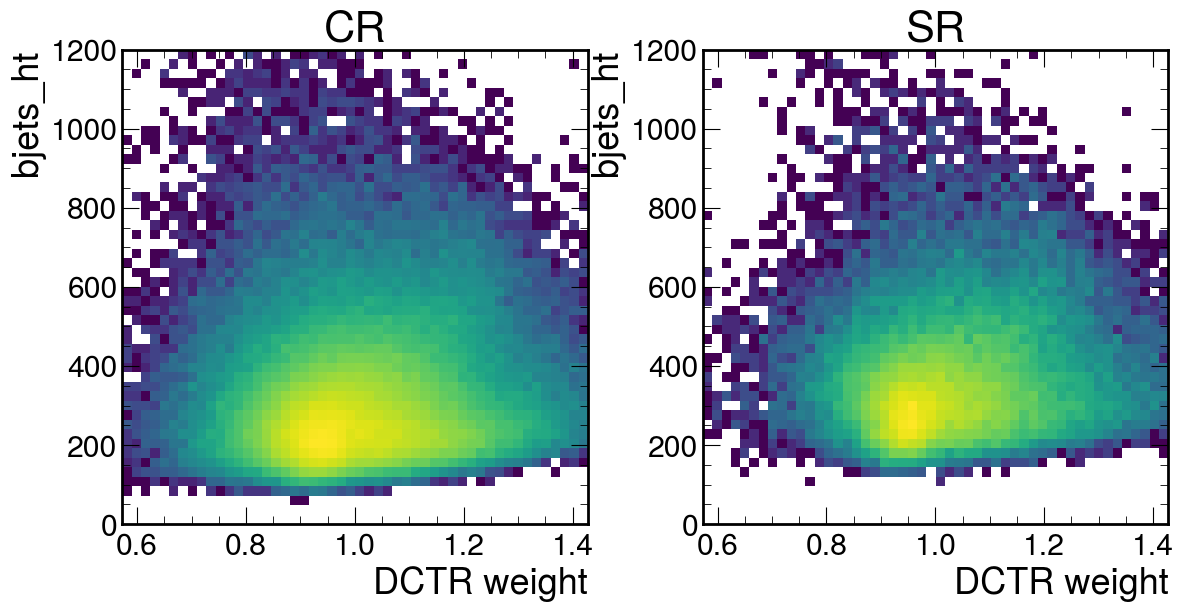

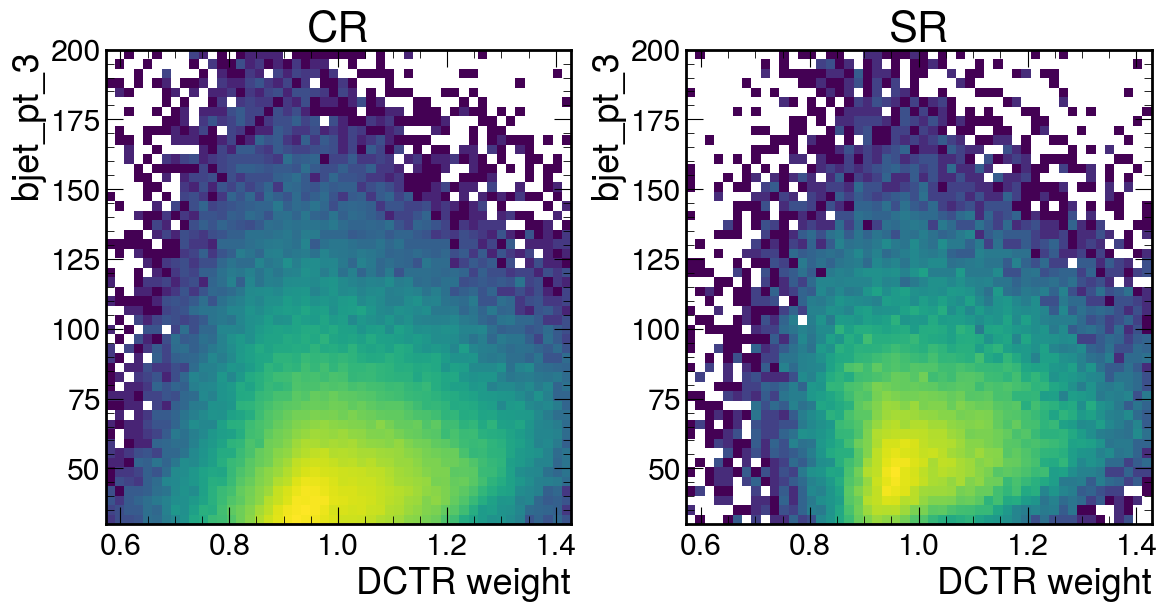

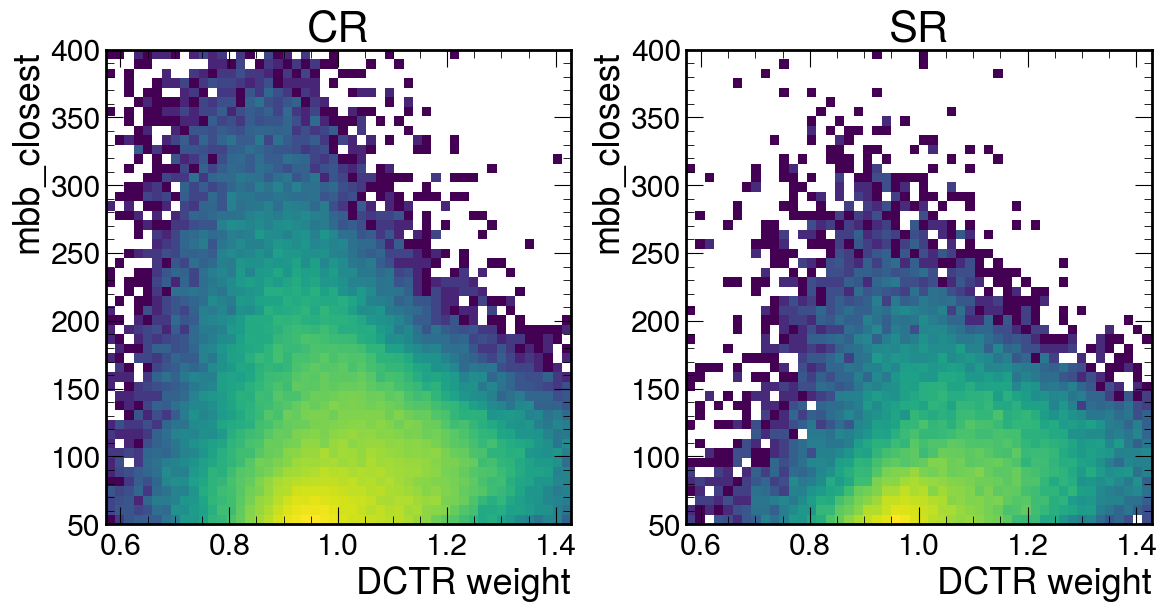

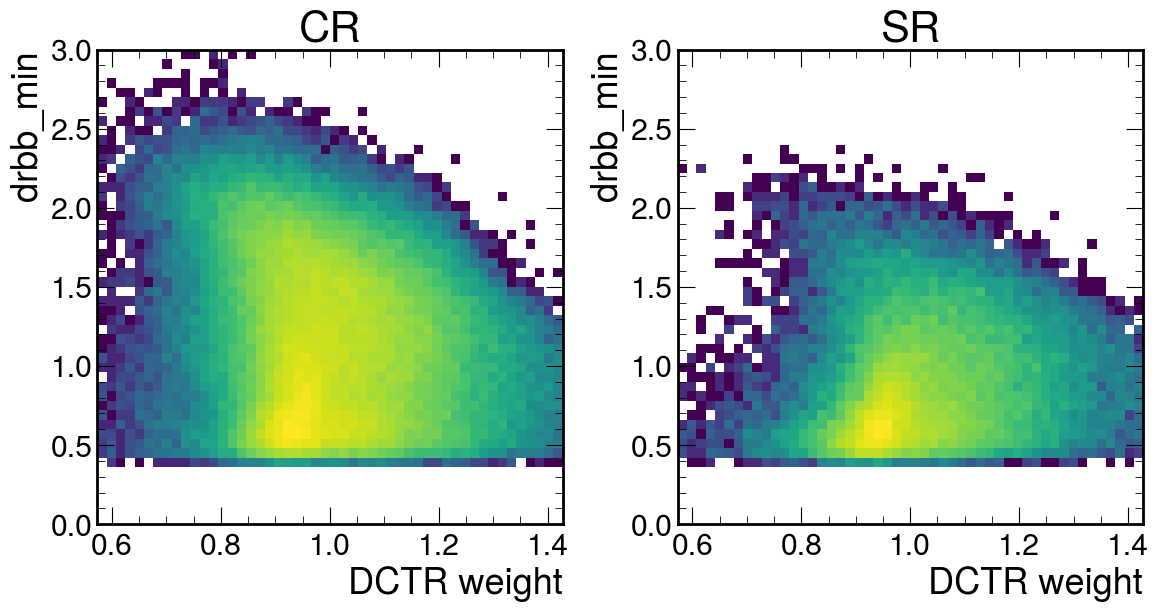

In [40]:
for col in cols:
    f, axs = plt.subplots(1, 2, figsize=(12, 6))
    plt.tight_layout()
    axs[0].hist2d(ak.to_numpy(df[mask_ttbb & isCR].dctr_weight),
                  ak.to_numpy(df.events[col][mask_ttbb & isCR]),
                  range=(w_range, hist_settings[col][1:]), 
                  bins=50, density=True, norm=LogNorm())
    axs[0].set_title("CR")
    axs[0].set_xlabel("DCTR weight")
    axs[0].set_ylabel(col)


    axs[1].hist2d(ak.to_numpy(df[mask_ttbb & isSR].dctr_weight),
                  ak.to_numpy(df.events[col][mask_ttbb & isSR]),
                  range=(w_range, hist_settings[col][1:]), 
                  bins=50, density=True, norm=LogNorm())
    axs[1].set_title("SR")
    axs[1].set_xlabel("DCTR weight")
    axs[1].set_ylabel(col)
    plt.savefig(save_folder+f'/dctr_vs_{col}_ttbb_2024.png')

In [41]:
# Split events in 33% quantiles of the DCTR weight
q = [1./3, 2./3]
weight_cut_incl = {}

# Mask for ttbb events in ttbb_CR with specific njet
mask_ttbb_nj = mask_ttbb & isCR
weights_incl = ak.to_numpy(df.dctr_weight[mask_ttbb_nj])

# Calculate quantiles
w_lo, w_hi = np.quantile(weights_incl, q)

# outer edges: [0, 3] as before, extended if needed so that every event falls in L, M or H (the weight can be < 0)
w_min = min(0., float(np.min(dctr_w_ttbb)))
w_max = max(3., float(np.nextafter(np.max(dctr_w_ttbb), np.inf)))
weight_cut_incl["inclusive"] = [(w_min, float(w_lo)), (float(w_lo), float(w_hi)), (float(w_hi), w_max)]

with open(os.path.join(save_folder, "dctr_quantiles_2024.json"), "w") as f:
    json.dump(weight_cut_incl, f, indent=4)
with open(os.path.join(model_folder, f"dctr_model_lambda{lambda_dctr}_quantiles_2024.json"), "w") as f:
    json.dump(weight_cut_incl, f, indent=4)

In [42]:
weight_cut_incl

{'inclusive': [(-236.48117065429688, 0.9405264258384705),
  (0.9405264258384705, 1.0542012055714924),
  (1.0542012055714924, 41.67221069335938)]}

In [43]:
njet = ak.num(df.JetGood)
dctr_regions = {
    "L":  (df.dctr_weight >= weight_cut_incl["inclusive"][0][0])&\
          (df.dctr_weight < weight_cut_incl["inclusive"][0][1]),
    "M":  (df.dctr_weight >= weight_cut_incl["inclusive"][1][0])&\
          (df.dctr_weight < weight_cut_incl["inclusive"][1][1]),
    "H":  (df.dctr_weight >= weight_cut_incl["inclusive"][2][0])&\
          (df.dctr_weight < weight_cut_incl["inclusive"][2][1]),
}
          

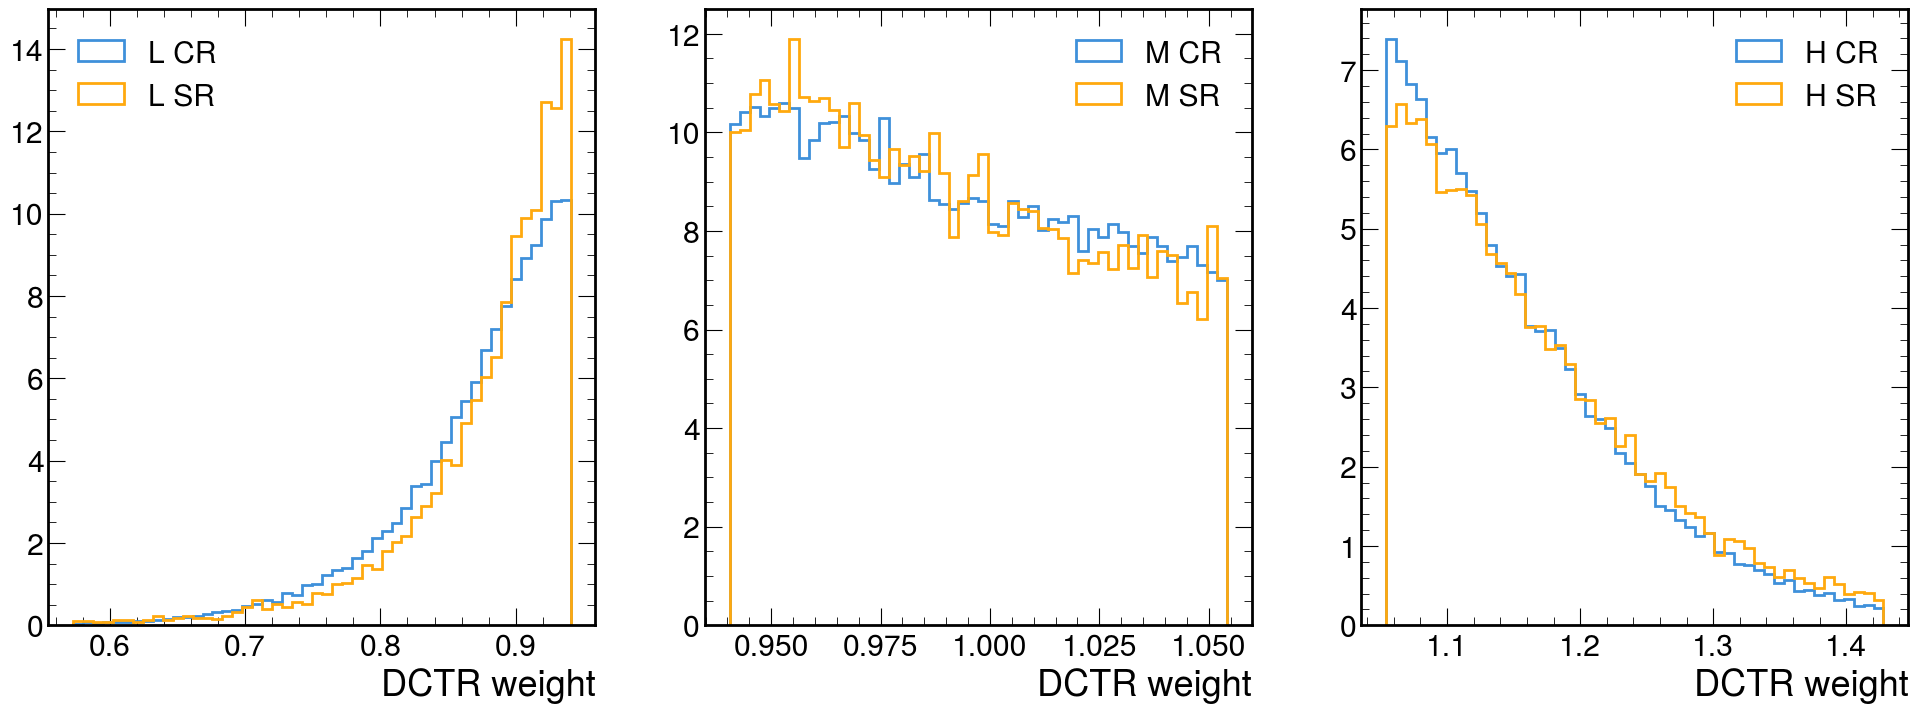

In [44]:
# inclusive dctr weight by quantiles in CR e SR
# plotting range of each region: its tercile edges, restricted to the DCTR weight range of the ttbb events
dctr_ranges = [[max(lo, w_range[0]), min(hi, w_range[1])] for lo, hi in weight_cut_incl["inclusive"]]

f, (ax, bx, cx ) = plt.subplots(1, 3, figsize=(24,8))
ax.hist(df[mask_ttbb & dctr_regions["L"] & isCR].dctr_weight, range=dctr_ranges[0], bins=50,histtype="step", linewidth=2, color=CMAP_10[0], label="L CR", density=True )
ax.hist(df[mask_ttbb & dctr_regions["L"] & isSR].dctr_weight, range=dctr_ranges[0], bins=50,histtype="step", linewidth=2, color=CMAP_10[1], label="L SR", density=True  )
bx.hist(df[mask_ttbb & dctr_regions["M"] & isCR].dctr_weight, range=dctr_ranges[1], bins=50,histtype="step", linewidth=2, color=CMAP_10[0], label="M CR", density=True  )
bx.hist(df[mask_ttbb & dctr_regions["M"] & isSR].dctr_weight, range=dctr_ranges[1], bins=50,histtype="step", linewidth=2, color=CMAP_10[1], label="M SR", density=True  )
cx.hist(df[mask_ttbb & dctr_regions["H"] & isCR].dctr_weight, range=dctr_ranges[2], bins=50,histtype="step", linewidth=2, color=CMAP_10[0], label="H CR", density=True  )
cx.hist(df[mask_ttbb & dctr_regions["H"] & isSR].dctr_weight, range=dctr_ranges[2], bins=50,histtype="step", linewidth=2, color=CMAP_10[1], label="H SR", density=True  )
ax.set_xlabel("DCTR weight")
bx.set_xlabel("DCTR weight")
cx.set_xlabel("DCTR weight")
ax.legend()
bx.legend()
cx.legend()
#f.suptitle(f"{njets}", fontsize="large")

f.savefig(os.path.join(save_folder, "dctr_weight_quantiles_CR_SR_2024.png"),dpi=300)

In [45]:
def plot_comparison_SR_DR(variable, mask, output_folder, text="", density=True, apply_weight=False):
    f, (ax, bx, cx,r1x, r2x) = plt.subplots(1, 5, figsize=(40,8))
    nbins, range0, range1 = hist_settings[variable]
    ax.hist(df.events[variable][mask & dctr_regions["L"] & isCR], bins=nbins, density=density, range=(range0,range1),
                            label="CR", color=CMAP_10[0],  histtype="step", linewidth=2,
           weights= weights[mask & dctr_regions["L"] & isCR]);
    bx.hist(df.events[variable][mask & dctr_regions["M"]& isCR], bins=nbins, density=density, range=(range0,range1),
                                        label="CR", color=CMAP_10[0], histtype="step", linewidth=2,
           weights= weights[mask & dctr_regions["M"] & isCR]);
    cx.hist(df.events[variable][mask & dctr_regions["H"]& isCR], bins=nbins, density=density, range=(range0,range1),
                                          label="CR", color=CMAP_10[0], histtype="step", linewidth=2,
              weights= weights[mask & dctr_regions["H"] & isCR]);
    
    ax.hist(df.events[variable][mask & dctr_regions["L"] & isSR], bins=nbins, density=density, range=(range0,range1),
                           label="SR", color=CMAP_10[1],  histtype="step", linewidth=2.,
            weights= weights[mask & dctr_regions["L"] & isSR]);
    bx.hist(df.events[variable][mask & dctr_regions["M"]& isSR], bins=nbins, density=density, range=(range0,range1),
                            label="SR", color=CMAP_10[1], histtype="step", linewidth=2,
                        weights= weights[mask & dctr_regions["M"] & isSR]);
    cx.hist(df.events[variable][mask & dctr_regions["H"]& isSR], bins=nbins, density=density, range=(range0,range1),
                                          label="SR", color=CMAP_10[1], histtype="step", linewidth=2,
            weights= weights[mask & dctr_regions["H"] &isSR]);

    r1x.hist(df.events[variable][mask & dctr_regions["L"] & isCR], bins=nbins, density=density, range=(range0,range1),
                            label="L", color=CMAP_10[0], histtype="step", linewidth=2,
                weights= weights[mask & dctr_regions["L"] & isCR]);
    r1x.hist(df.events[variable][mask & dctr_regions["M"]& isCR], bins=nbins, density=density, range=(range0,range1),
                                        label="M", color=CMAP_10[1], histtype="step", linewidth=2,
                weights= weights[mask & dctr_regions["M"] & isCR]);
    r1x.hist(df.events[variable][mask & dctr_regions["H"]& isCR], bins=nbins, density=density, range=(range0,range1),
                                          label="H", color=CMAP_10[2], histtype="step", linewidth=2,
                weights= weights[mask & dctr_regions["H"] & isCR]);

    r2x.hist(df.events[variable][mask & dctr_regions["L"] & isSR], bins=nbins, density=density, range=(range0,range1),
                            label="L", color=CMAP_10[0], histtype="step", linewidth=2,
                    weights= weights[mask & dctr_regions["L"] & isSR]);
    r2x.hist(df.events[variable][mask & dctr_regions["M"]& isSR], bins=nbins, density=density, range=(range0,range1),
                                        label="M", color=CMAP_10[1], histtype="step", linewidth=2,
                weights= weights[mask & dctr_regions["M"] & isSR]);
    r2x.hist(df.events[variable][mask & dctr_regions["H"]& isSR], bins=nbins, density=density, range=(range0,range1),
                                          label="H", color=CMAP_10[2], histtype="step", linewidth=2,
              weights= weights[mask & dctr_regions["H"] & isSR]);

    ax.set_xlabel(variable)
    bx.set_xlabel(variable)
    cx.set_xlabel(variable)
    r1x.set_xlabel(variable)
    r2x.set_xlabel(variable)
    ax.set_title("DCTR Low", fontsize="small")
    bx.set_title("DCTR Medium", fontsize="small")
    cx.set_title("DCTR High", fontsize="small")
    r1x.set_title("CR comparison", fontsize="small")
    r2x.set_title("SR comparison", fontsize="small")
    ax.legend()
    bx.legend()
    cx.legend()
    r1x.legend()
    r2x.legend()
    f.suptitle(f"{text}", fontsize="large")
    plt.tight_layout()
    plt.savefig(f"{output_folder}/dctr_shape_comparison_{variable}_{text}_2024.pdf")
    plt.savefig(f"{output_folder}/dctr_shape_comparison_{variable}_{text}_2024.png")
    plt.show()
    plt.close()

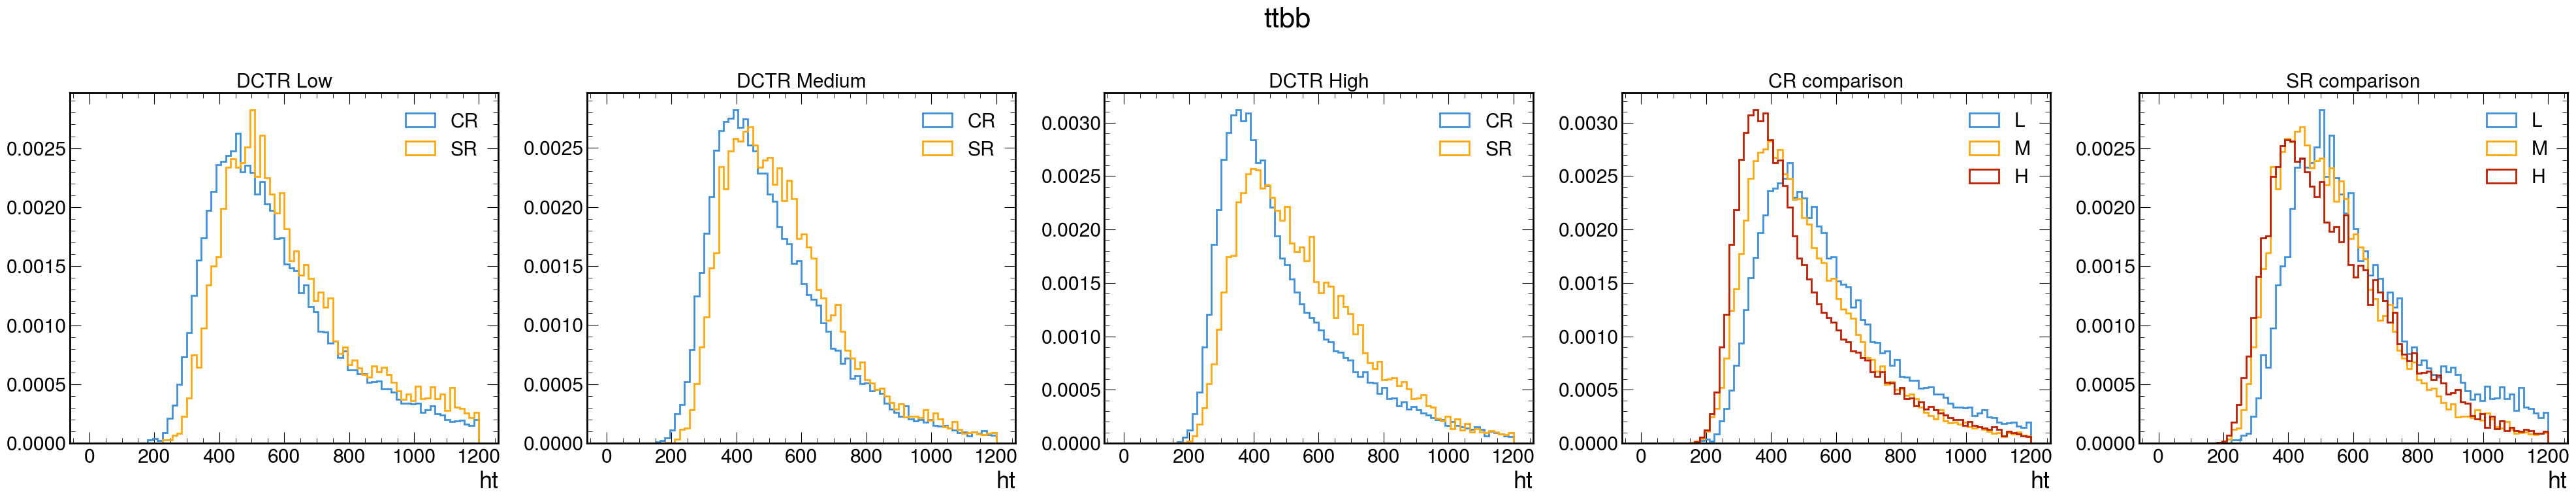

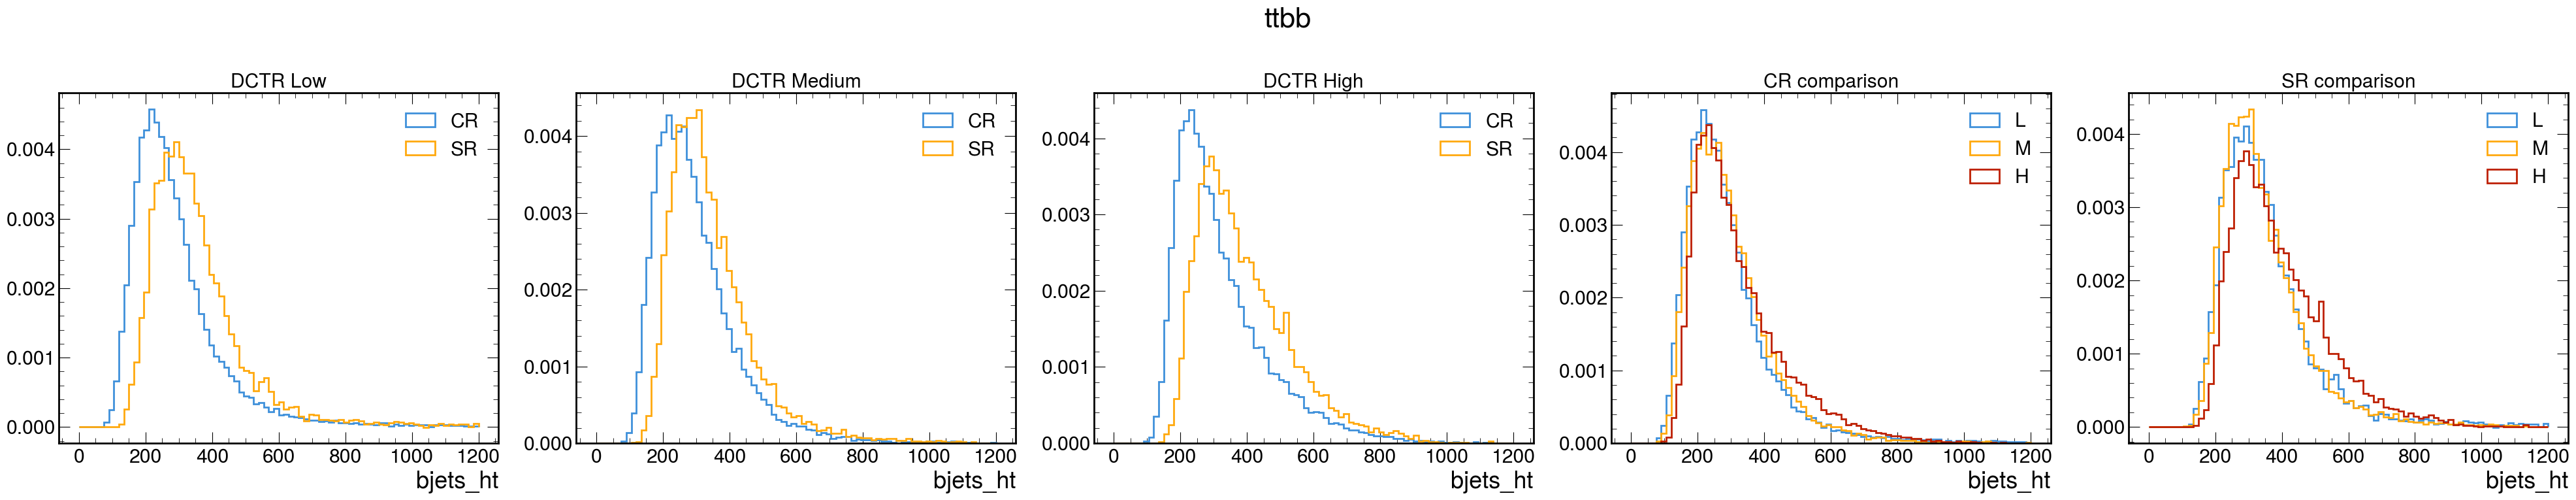

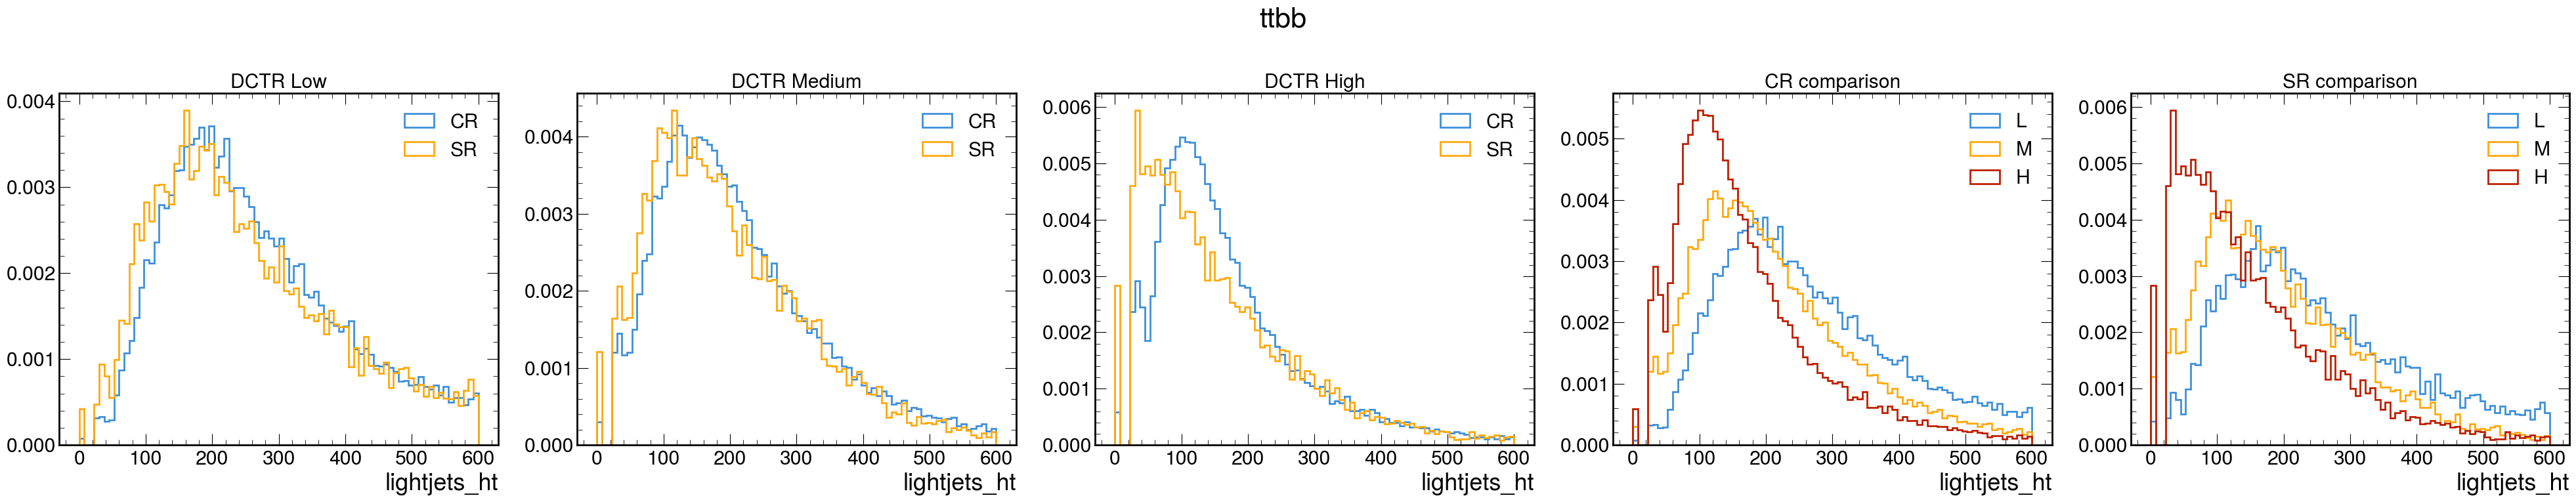

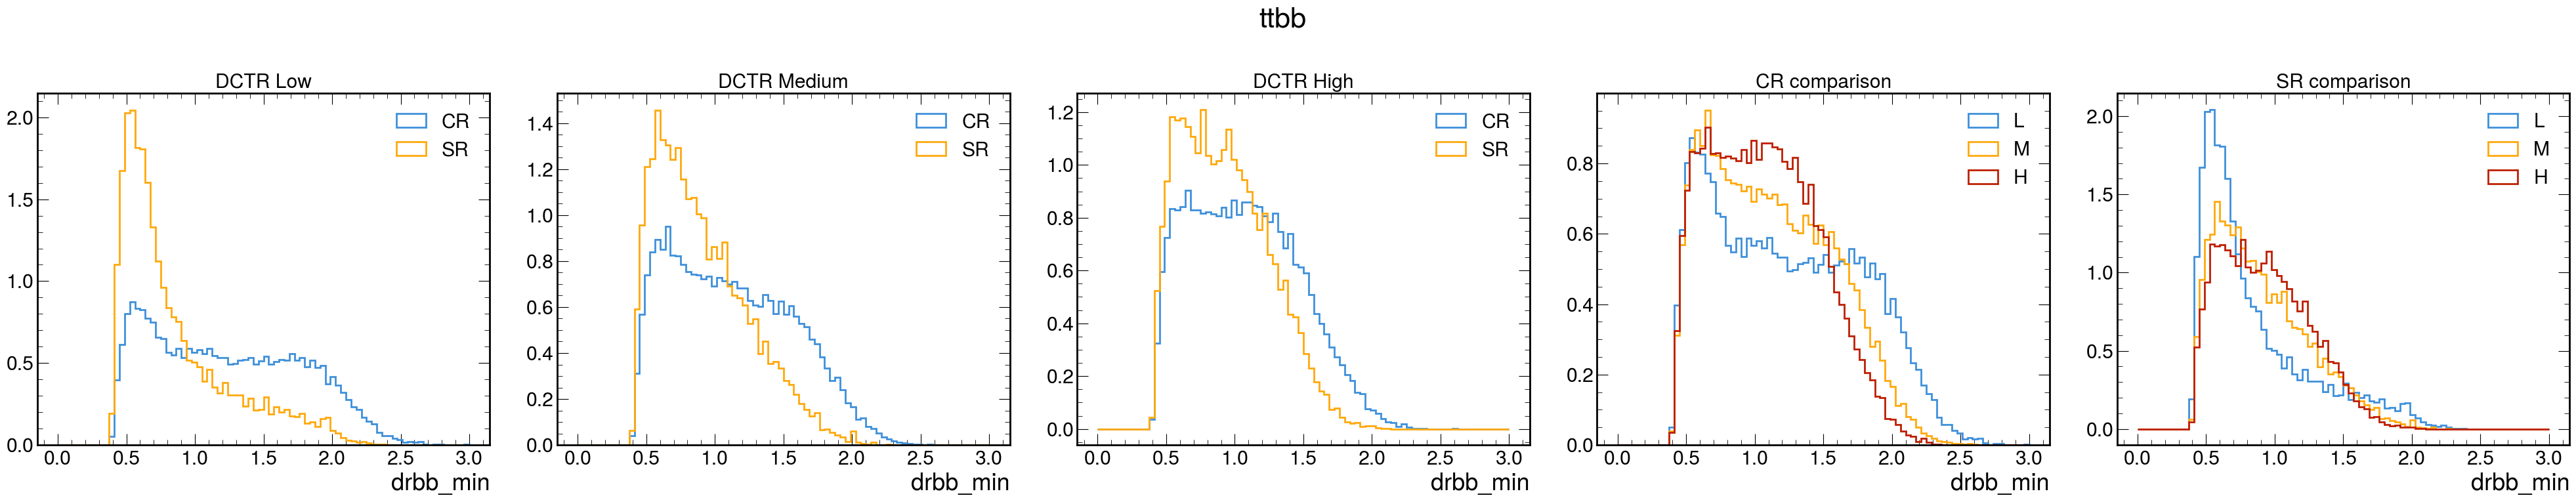

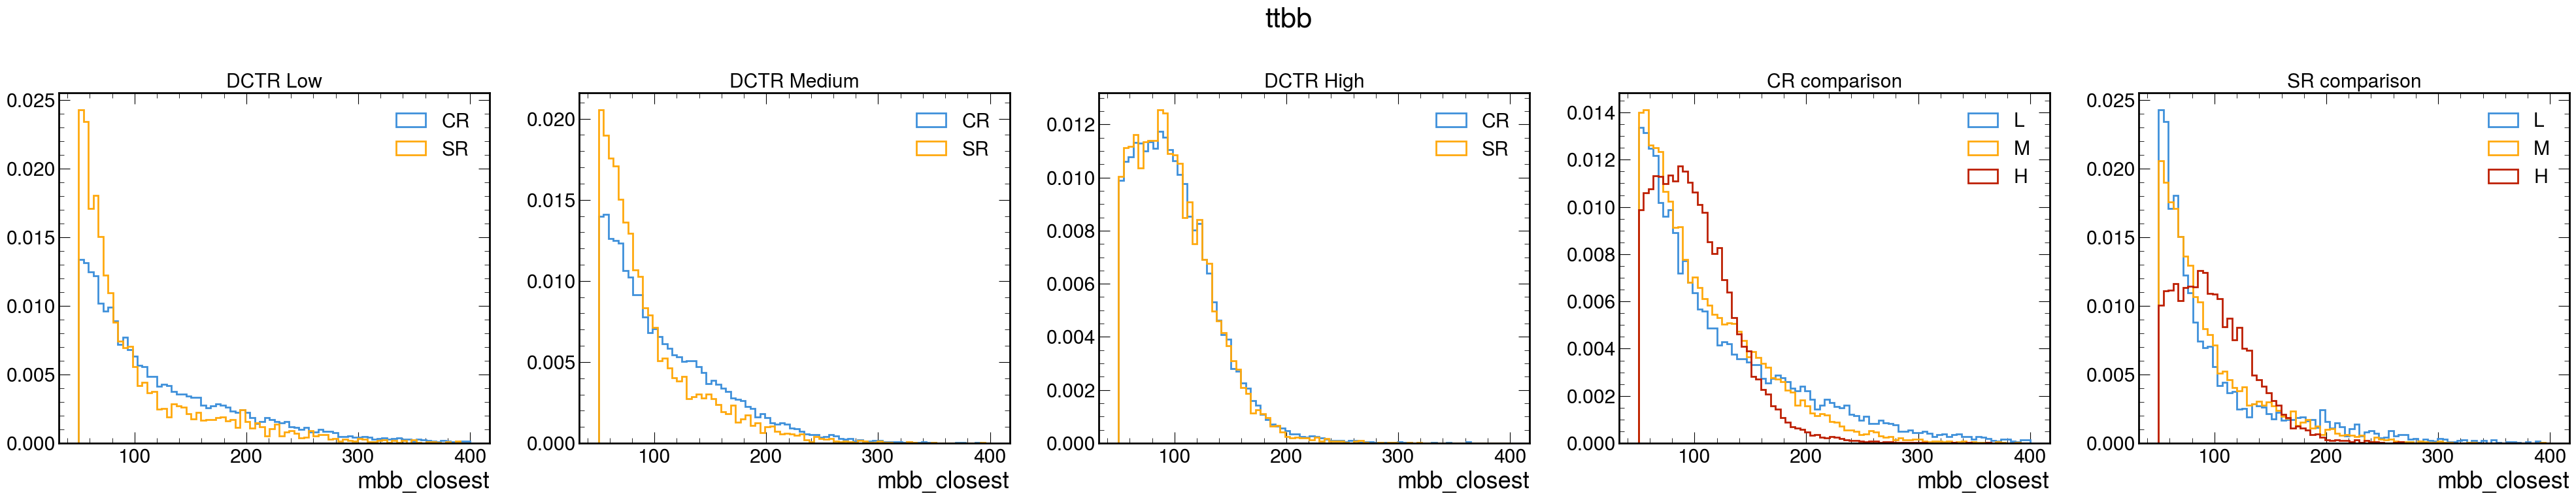

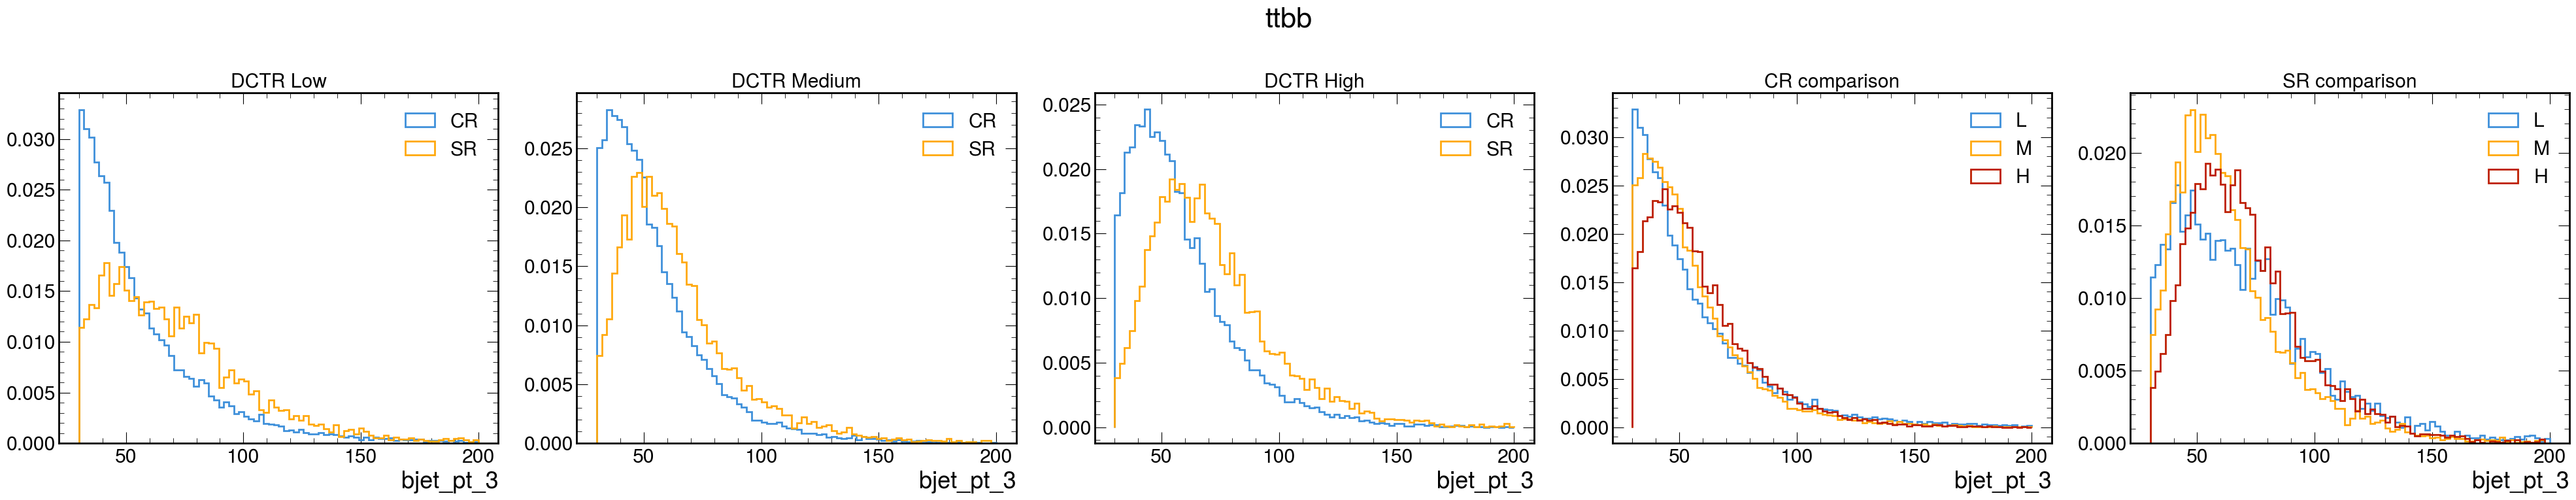

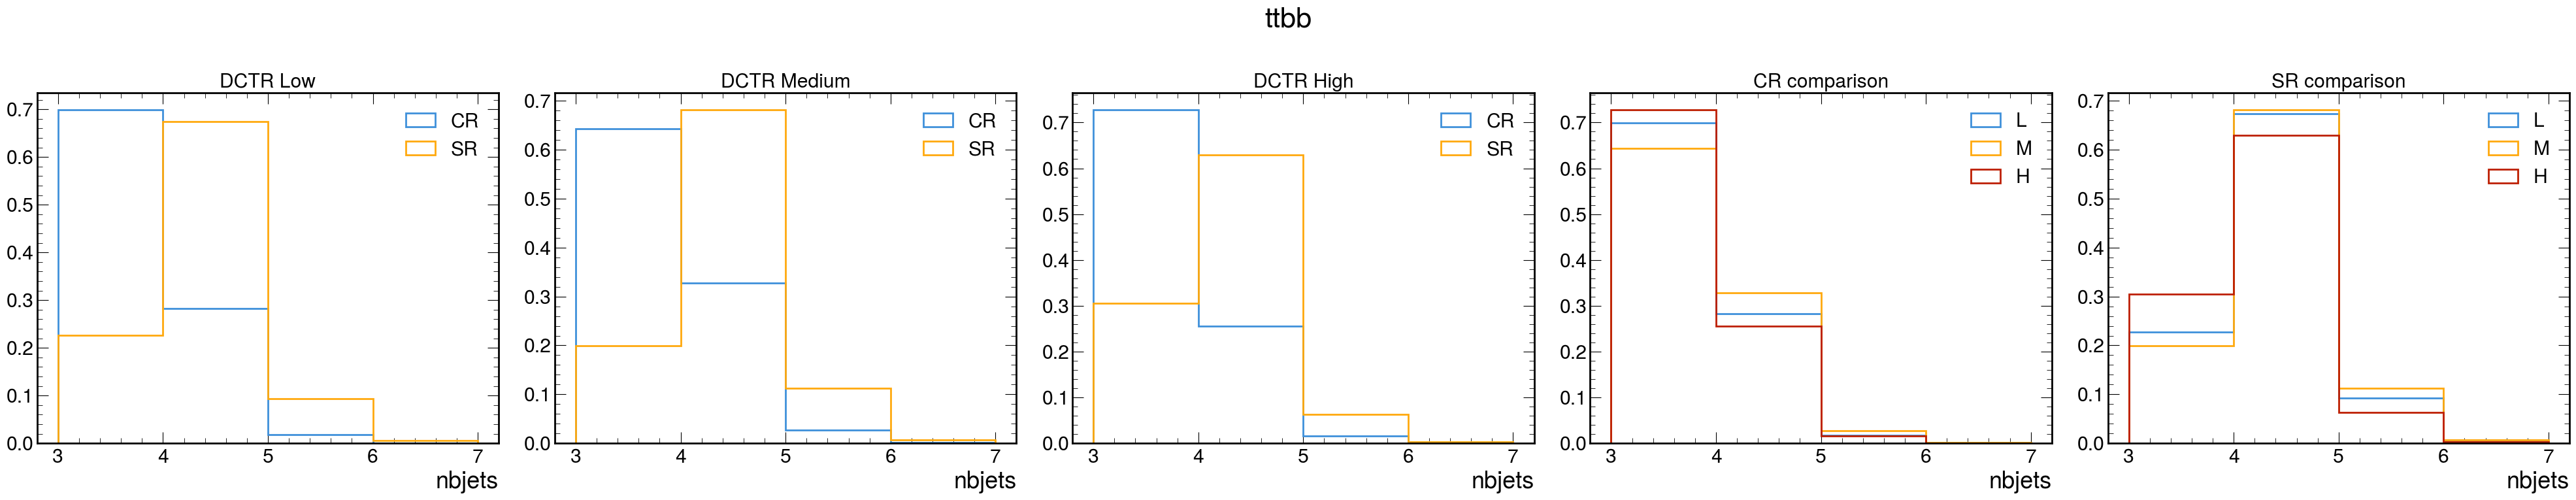

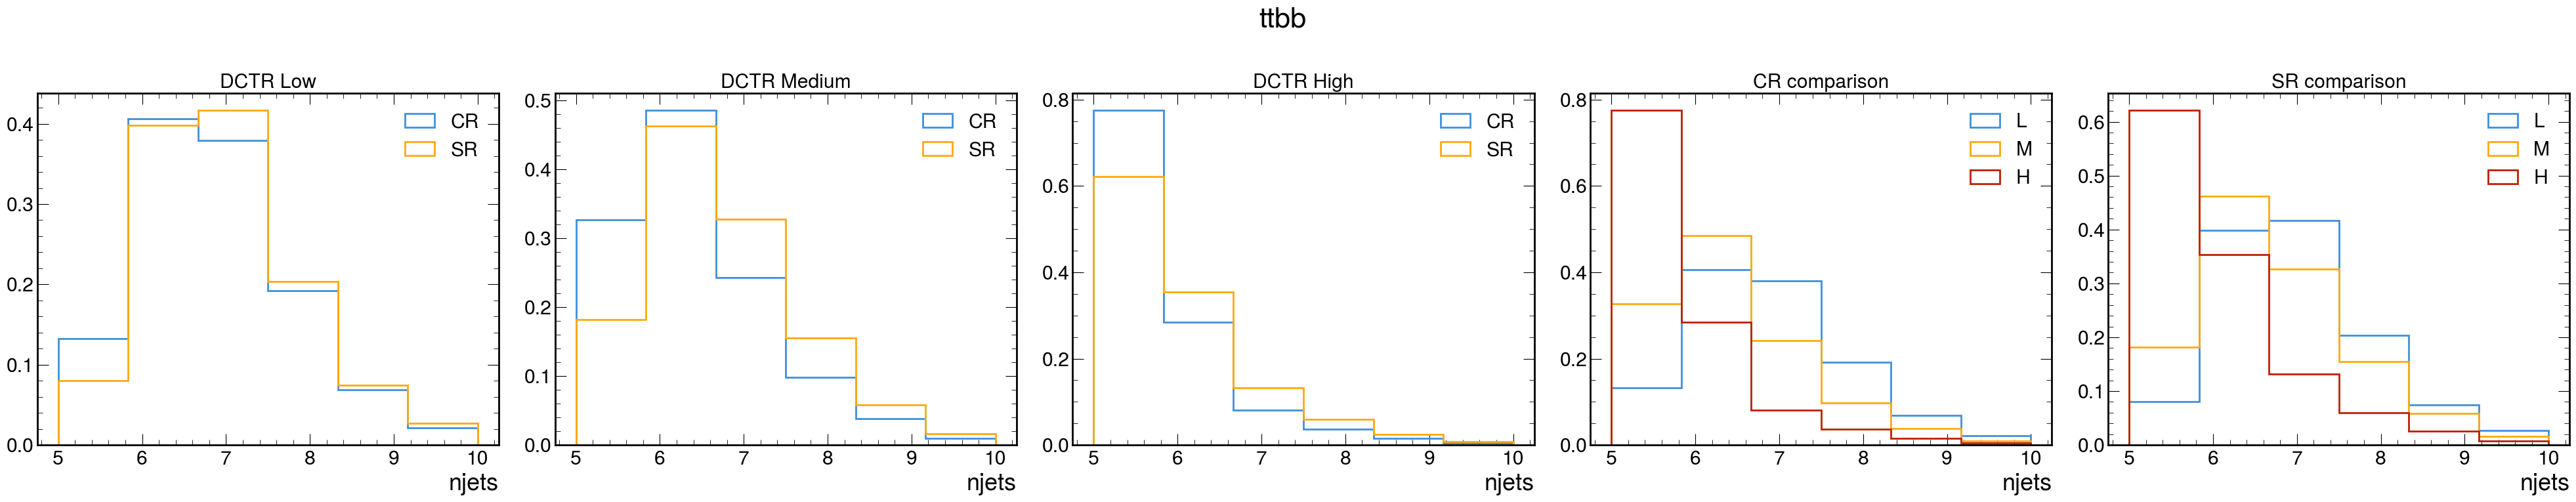

In [46]:
for variable in hist_settings.keys():
    plot_comparison_SR_DR(variable, mask_ttbb,  text="ttbb", output_folder=save_folder, density=True)

In [ ]:
def plot_corr_corner(cols, ranges, bins, colors, initial_mask,title, output_folder, legloc="upper right", nlevels=5, bins_contour=15):

    f, axs = plt.subplots(len(cols), len(cols), figsize=(6*len(cols), 6*len(cols)), dpi=70)
    
    mask_L = initial_mask & dctr_regions["L"]
    mask_H = initial_mask & dctr_regions["H"]
    mask_M = initial_mask & dctr_regions["M"]

    for ic in range(len(cols)):
        for jc in range(len(cols)):
            if ic == jc:
                axs[ic][jc].hist( ak.to_numpy(df.events[cols[ic]][mask_L]),
                                    weights=ak.to_numpy(weights[mask_L]),
                                    bins=bins[ic], range=ranges[ic], histtype="step", linewidth=2,
                                label="L", color=colors["L"], density=True)
                axs[ic][jc].hist( ak.to_numpy(df.events[cols[ic]][mask_M]),
                                    weights=ak.to_numpy(weights[mask_M]),
                                    bins=bins[ic], range=ranges[ic], histtype="step", linewidth=2,
                                label="M",color=colors["M"], density=True)
                axs[ic][jc].hist( ak.to_numpy(df.events[cols[ic]][mask_H]),
                                    weights=ak.to_numpy(weights[mask_H]),
                                    bins=bins[ic], range=ranges[ic], histtype="step", linewidth=2,
                                label="H",color=colors["H"], density=True)
                if jc == len(cols)-1:
                        axs[ic][jc].set_xlabel(cols[ic])
                if ic == 0:
                    axs[ic][jc].set_ylabel(cols[ic])
                axs[ic][jc].legend()
            
            # elif jc > ic:
            #     axs[ic][jc].remove()
            #     continue
            
            else:
                col1 = cols[jc]
                col2 = cols[ic]
                histL, xedges, yedges = np.histogram2d(  
                                ak.to_numpy(df.events[col1][mask_L]),
                                ak.to_numpy(df.events[col2][mask_L]), 
                                weights = ak.to_numpy(weights[mask_L]),
                                bins=bins_contour, range=(ranges[jc], ranges[ic]), 
                                density=True)
                
                histM, xedges, yedges = np.histogram2d(  
                                ak.to_numpy(df.events[col1][mask_M]),
                                ak.to_numpy(df.events[col2][mask_M]), 
                                weights = ak.to_numpy(weights[mask_M]),
                                bins=bins_contour, range=(ranges[jc], ranges[ic]), 
                                density=True)
                
                histH, xedges, yedges = np.histogram2d(  
                                ak.to_numpy(df.events[col1][mask_H]),
                                ak.to_numpy(df.events[col2][mask_H]), 
                                weights = ak.to_numpy(weights[mask_H]),
                                bins=bins_contour, range=(ranges[jc], ranges[ic]), 
                                density=True)
                
                x_centers = (xedges[:-1] + xedges[1:]) / 2
                y_centers = (yedges[:-1] + yedges[1:]) / 2
                X, Y = np.meshgrid(x_centers, y_centers)
                
                CS1 = axs[ic][jc].contour(X, Y, histL.T, nlevels,colors="blue") #L
                CS2 = axs[ic][jc].contour(X, Y, histM.T, nlevels, colors="black") #M
                CS3 = axs[ic][jc].contour(X, Y, histH.T, nlevels,colors="red")  #H
        
                plt.clabel(CS1, inline=True, fontsize=8, fmt='%1.0f')
                plt.clabel(CS2, inline=True, fontsize=8, fmt='%1.0f')
                plt.clabel(CS3, inline=True, fontsize=8, fmt='%1.0f')
                
                legend_elements = [
                    Line2D([0], [0], color='blue', label='L'),
                    Line2D([0], [0], color='black',  label='M'),
                    Line2D([0], [0], color='red', label='H')
                ]
                axs[ic][jc].legend(handles=legend_elements, loc=legloc)
                
                if jc == 0:
                    axs[ic][jc].set_ylabel(col2)
                if ic == len(cols)-1:
                    axs[ic][jc].set_xlabel(col1)
        
    f.suptitle(f"{title}", fontsize="large")
    plt.tight_layout()
    if output_folder:
        os.makedirs(output_folder, exist_ok=True)
        plt.savefig(f"{output_folder}/dctr_cornerplot_{title}_2024.pdf")
        plt.savefig(f"{output_folder}/dctr_cornerplot_{title}_2024.png")

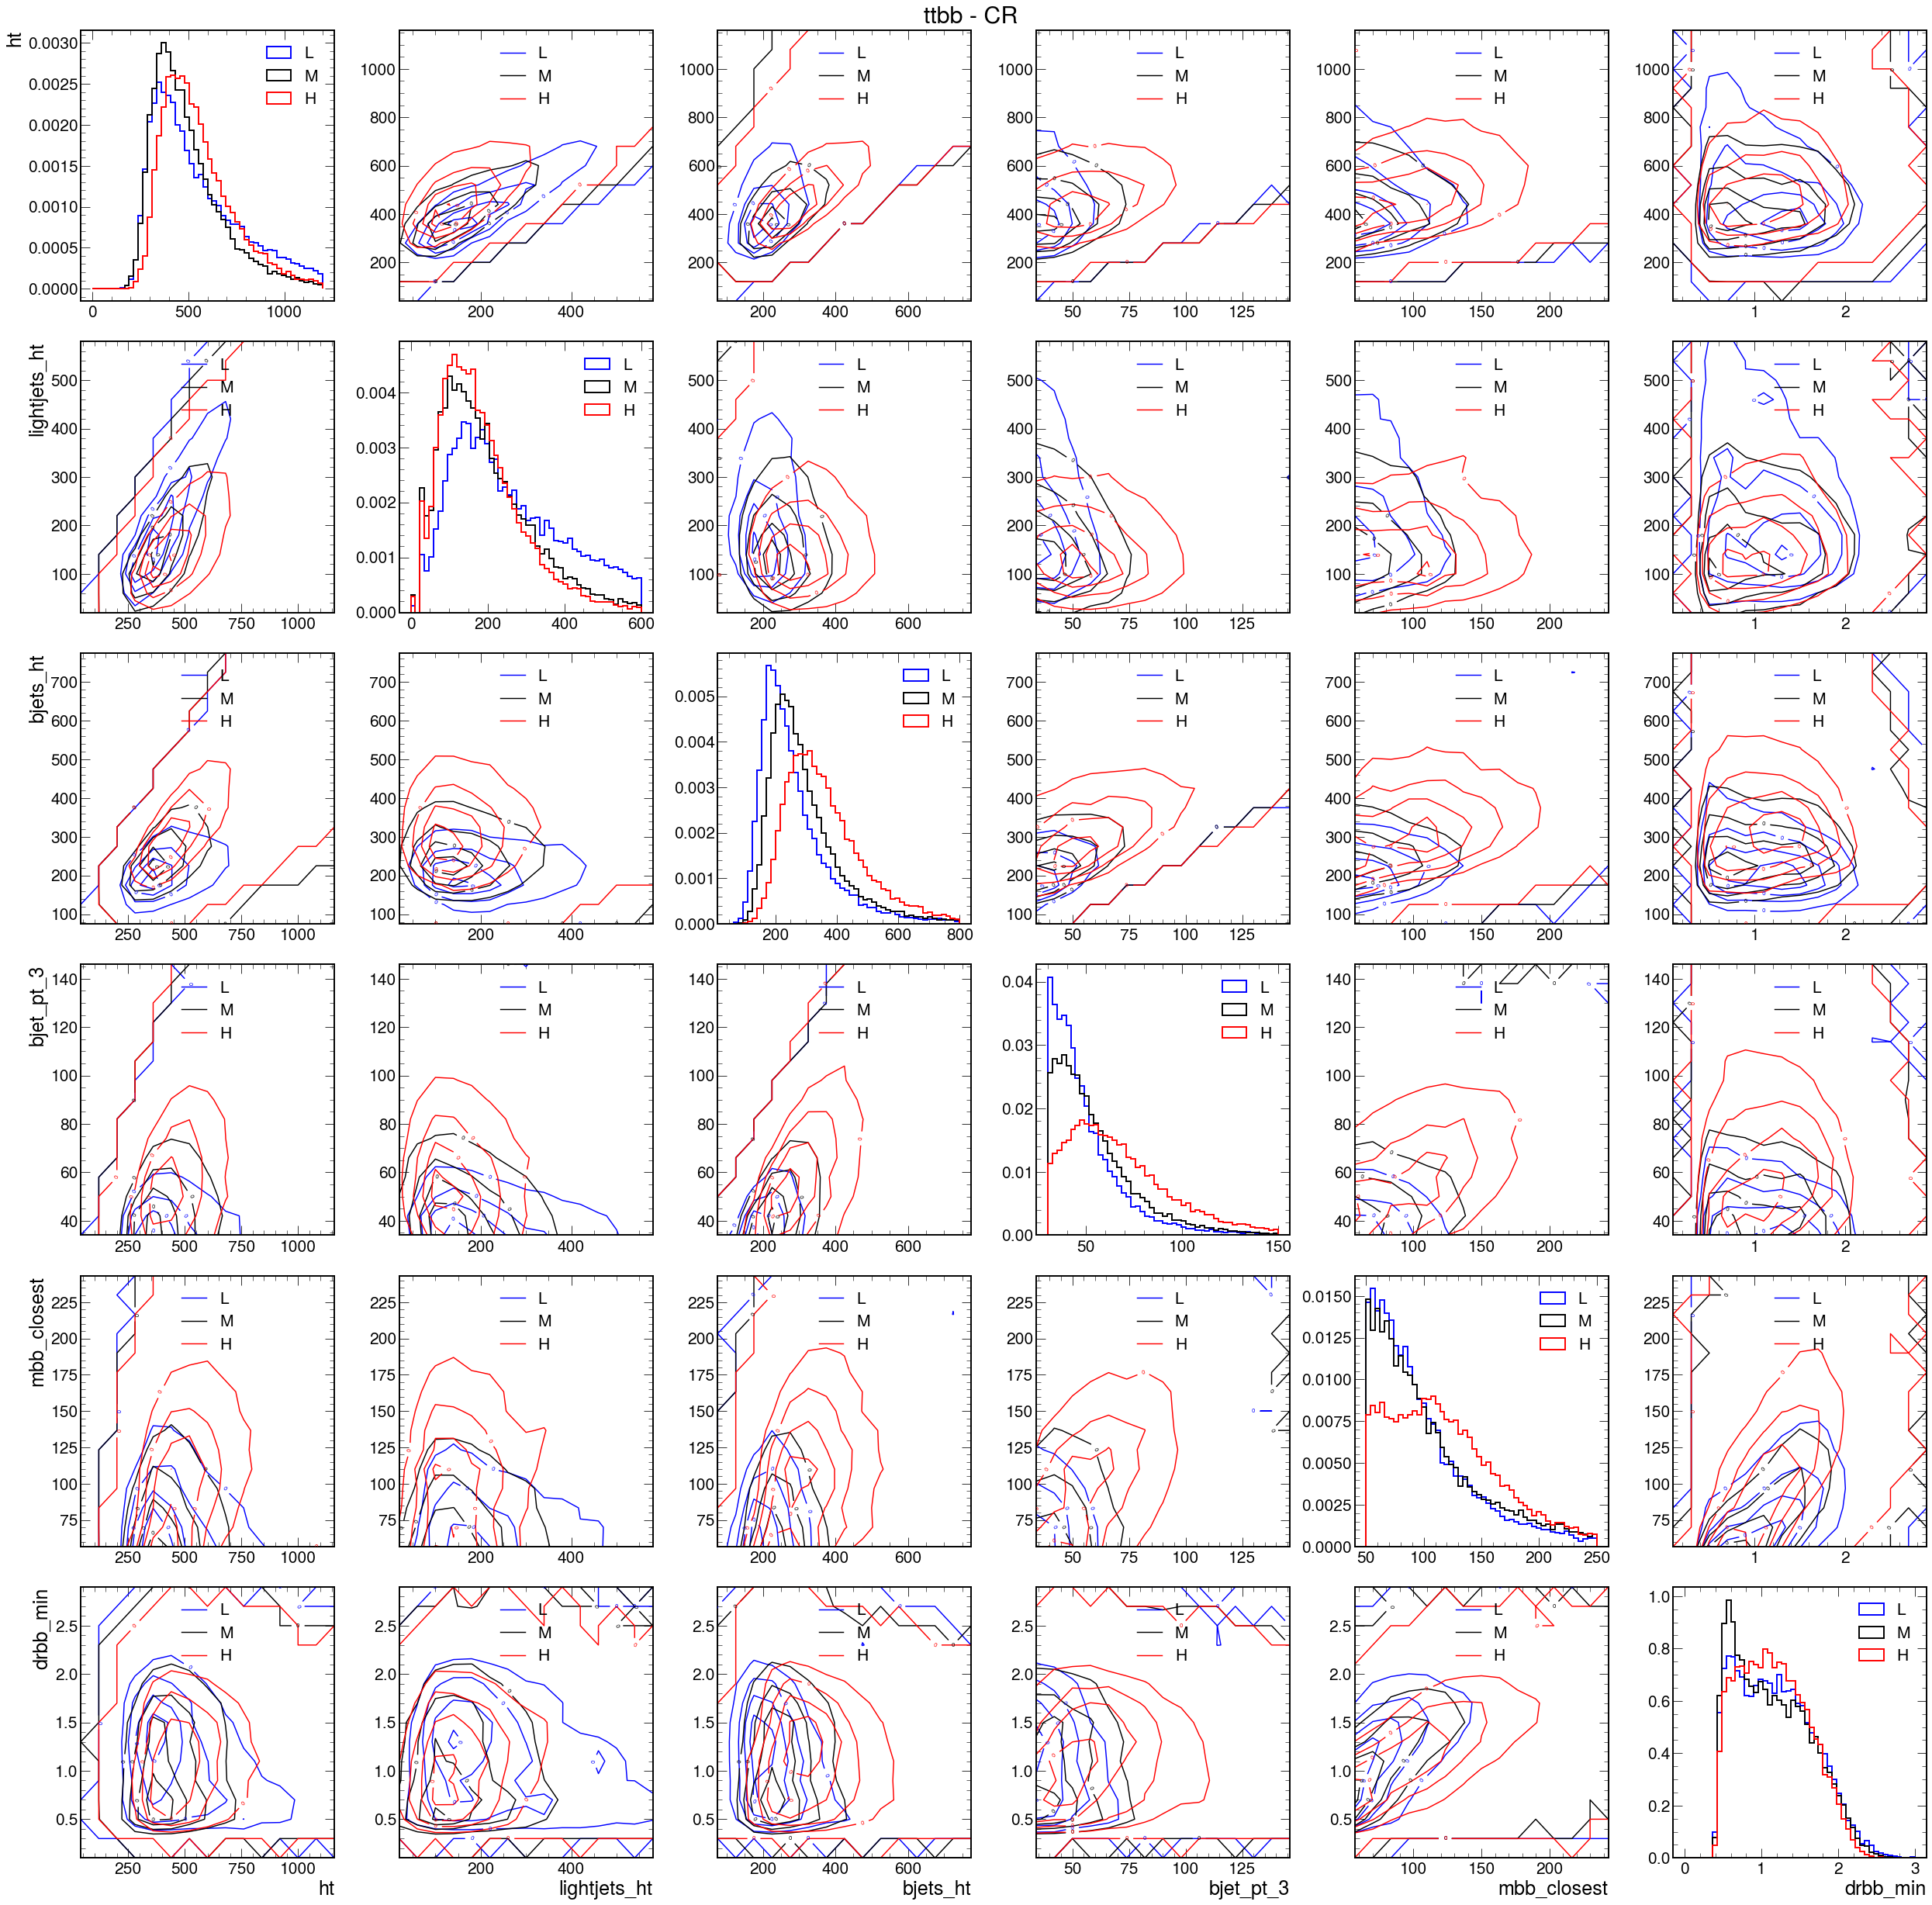

In [90]:
hist_settings_2 = {
    "ht" : (50, 0, 1200),
    "bjets_ht" : (50,50,800),
    "lightjets_ht": (50, 0, 600),
    "drbb_min": (50, 0, 3),
    "mbb_closest": (50,50, 250),
    "bjet_pt_3": (50, 30, 150),
}
columns_to_plot = [ k for k in cols if k not in["nbjets"]]
ranges= [hist_settings_2[k][1:] for k in columns_to_plot]
bins = [hist_settings_2[k][0] for k in columns_to_plot]
colors = {"H":"red","M":"black", "L":"blue"}

plot_corr_corner(columns_to_plot, ranges, bins, colors, initial_mask=(mask_ttbb&isCR), legloc="upper center", title="ttbb - CR", nlevels=4, bins_contour=15, output_folder=save_folder)


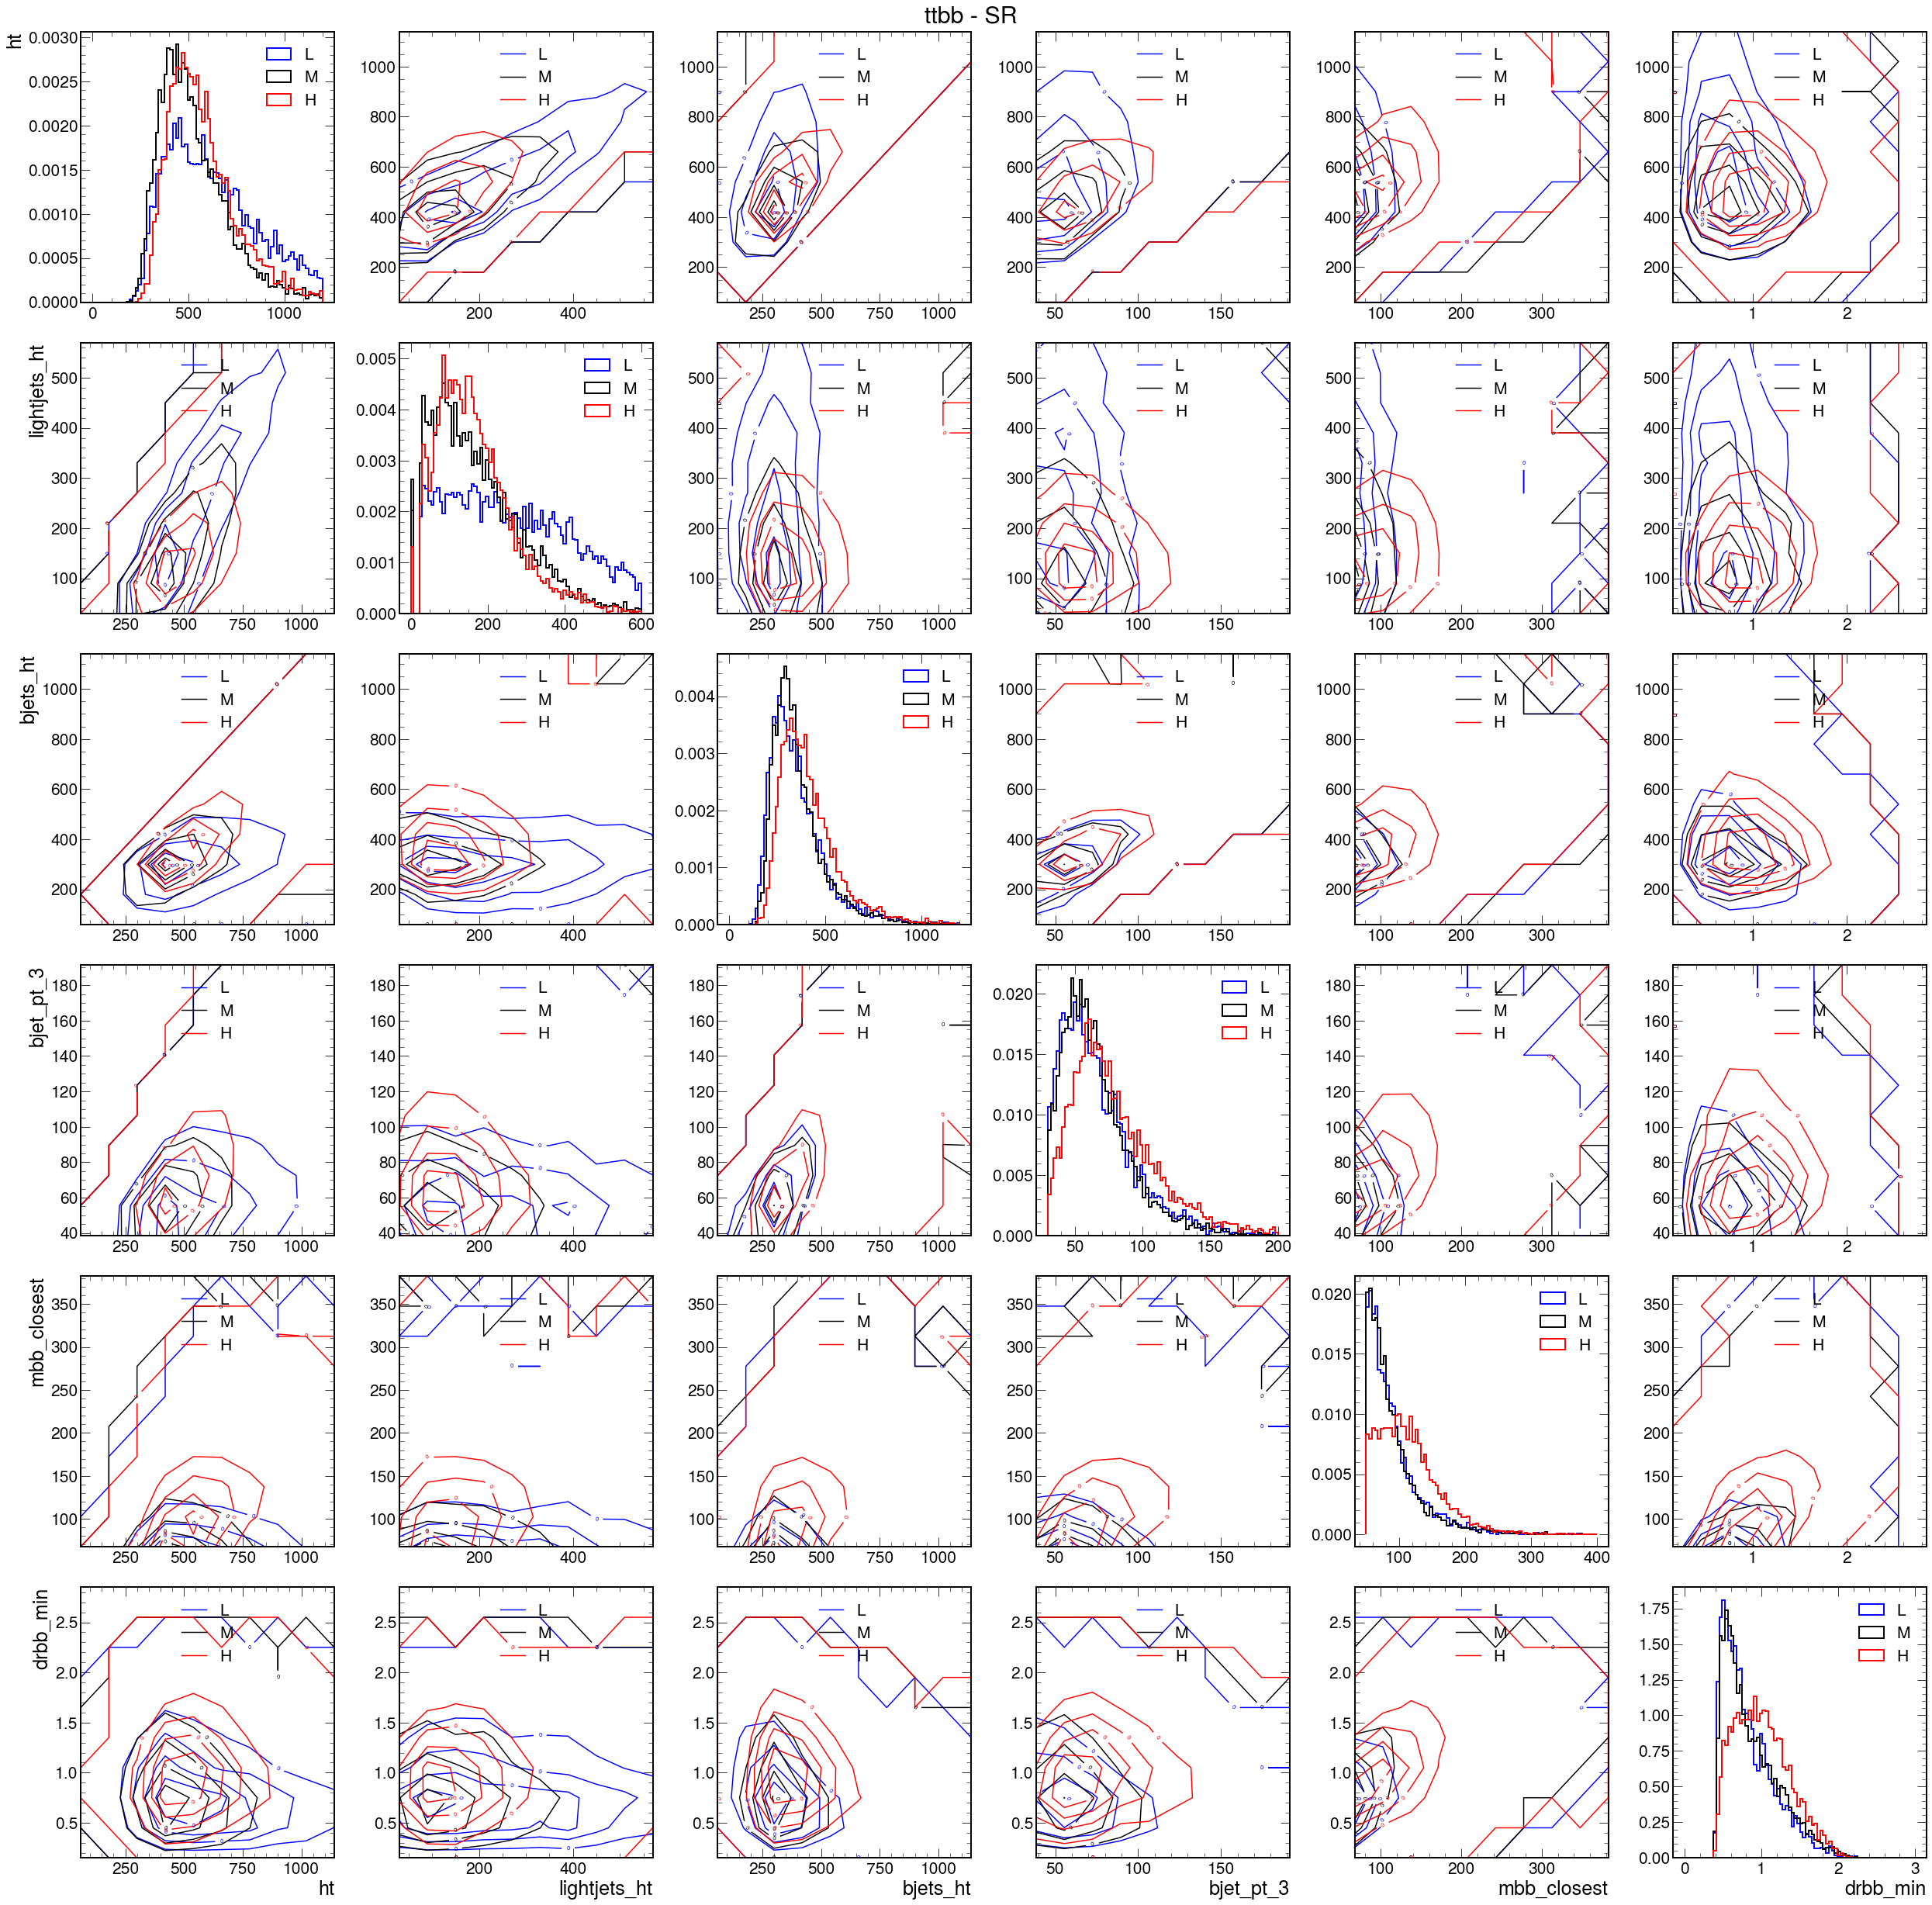

In [91]:
hist_settings_2 = {
    "ht" : (30, 0, 1200),
    "bjets_ht" : (30,50,800),
    "lightjets_ht": (30, 0, 600),
    "drbb_min": (30, 0, 3),
    "mbb_closest": (30,50, 250),
    "bjet_pt_3": (30, 30, 150),
}
columns_to_plot = [ k for k in cols if k not in["nbjets"]]
ranges= [hist_settings[k][1:] for k in columns_to_plot]
bins = [hist_settings[k][0] for k in columns_to_plot]
colors = {"H":"red","M":"black", "L":"blue"}

plot_corr_corner(columns_to_plot, ranges, bins, colors, initial_mask=(mask_ttbb&isSR), legloc="upper center", title="ttbb - SR", nlevels=4, bins_contour=10, output_folder=save_folder)

In [ ]:
# closure test: ttbb yield reweighted with the DCTR weight vs data yield
# (masks re-defined here since mask_ttbb is overwritten above with the CR selection)
# NB: in training the ttbb class is scaled by reweight_factor = N(data - minor bkg) / N(ttbb) in the CR
# before fitting, so the classes are balanced and the DCTR weight only corrects the shape (weighted mean ~1).
# The normalisation is carried by reweight_factor, which has to be applied on top of the DCTR weight.
mask_mc = ak.to_numpy(df.data == 0)
is_data = ak.to_numpy(df.data == 1)
is_ttbb = mask_mc & ak.to_numpy(df.ttbb == 1)
is_data_minus_minor_bkg = ak.to_numpy(df.dctr == 1)
is_ttbb_dctr = ak.to_numpy(df.dctr == 0)  # ttbb class as defined in the DCTR training
dctr_w = ak.to_numpy(df.dctr_weight)
cr = ak.to_numpy(isCR)

print("ttbb definition (data==0 & ttbb==1) identical to training class (dctr==0):", np.array_equal(is_ttbb, is_ttbb_dctr))

# inclusive normalisation factor, computed as in the training (CR only)
reweight_factor = np.sum(weights[is_data_minus_minor_bkg & cr]) / np.sum(weights[is_ttbb_dctr & cr])
mean_dctr_w_cr = np.sum(weights[is_ttbb_dctr & cr] * dctr_w[is_ttbb_dctr & cr]) / np.sum(weights[is_ttbb_dctr & cr])
print(f"reweight_factor (CR): {reweight_factor:.4f}")
print(f"rf of the DCTR training (CR of the training dataset): {dctr_info['rf']:.4f}")
print(f"weighted mean of DCTR weight on ttbb in CR (should be ~1): {mean_dctr_w_cr:.4f}")

regions = {
    "inclusive": np.ones(len(weights), dtype=bool),
    "CR": cr,
    "SR": ak.to_numpy(isSR),
}

for region, reg_mask in regions.items():
    sel_ttbb = is_ttbb_dctr & reg_mask
    n_ttbb = np.sum(weights[sel_ttbb])
    n_ttbb_dctr = np.sum(weights[sel_ttbb] * dctr_w[sel_ttbb])
    n_ttbb_norm = reweight_factor * n_ttbb
    n_ttbb_norm_dctr = reweight_factor * n_ttbb_dctr
    n_data = np.sum(weights[is_data & reg_mask])
    n_data_minus_bkg = np.sum(weights[is_data_minus_minor_bkg & reg_mask])
    print(f"--- {region} ---")
    print(f"ttbb weighted events:                        {n_ttbb:.1f}")
    print(f"ttbb weighted events x reweight_factor:      {n_ttbb_norm:.1f}")
    print(f"ttbb weighted events x DCTR:                 {n_ttbb_dctr:.1f}")
    print(f"ttbb weighted events x reweight_factor x DCTR: {n_ttbb_norm_dctr:.1f}")
    print(f"data events:                                 {n_data:.1f}")
    print(f"data - minor bkg events:                     {n_data_minus_bkg:.1f}")
    print(f"ratio (ttbb x reweight_factor) / (data - minor bkg):        {n_ttbb_norm / n_data_minus_bkg:.4f}")
    print(f"ratio (ttbb x DCTR) / (data - minor bkg):                   {n_ttbb_dctr / n_data_minus_bkg:.4f}")
    print(f"ratio (ttbb x reweight_factor x DCTR) / (data - minor bkg): {n_ttbb_norm_dctr / n_data_minus_bkg:.4f}")